In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/eslamfawzysayed/h-c-model-r-forest-final-2/final_data_complete (1).xlsx


# 🚀 Random forest model—prediction and optimization

In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [3]:
import pandas as pd
from pandas import DataFrame
import math
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn import tree
import graphviz
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from collections import Counter
from pprint import pprint

In [4]:
import pandas as pd

# ==========================================
# 1. LOAD THE EXCEL FILE
# ==========================================
# Updated exact path provided by you
file_path = '/kaggle/input/datasets/eslamfawzysayed/h-c-model-r-forest-final-2/final_data_complete (1).xlsx'

# Load the data using read_excel because it is an .xlsx file
df = pd.read_excel(file_path, header=0)

# ==========================================
# 2. INSPECT THE DATA
# ==========================================
print("✅ File loaded successfully!")
print("\nColumn names (features):")
print(df.columns.tolist())

print("\nFirst 5 rows of data:")
print(df.head())

print("\nData Statistics for Numeric Columns:")
with pd.option_context('display.max_columns', None):
    print(df.describe(include='number'))

✅ File loaded successfully!

Column names (features):
['DOI', 'C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'Temprature(°C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

First 5 rows of data:
                                              DOI     C%    H%    N%    S%  \
0  https://doi.org/10.1016/j.apenergy.2017.09.019  34.78  3.93  5.04  1.15   
1  https://doi.org/10.1016/j.apenergy.2017.09.019  34.78  3.93  5.04  1.15   
2  https://doi.org/10.1016/j.apenergy.2017.09.019  34.78  3.93  5.04  1.15   
3  https://doi.org/10.1016/j.apenergy.2017.09.019  33.30  4.60  4.00  1.20   
4  https://doi.org/10.1016/j.apenergy.2017.09.019  33.30  4.60  4.00  1.20   

      O%   Ash%  Volatile matter%  Fixed carbon%  HHV (MJ/Kg)  ...  Nc(%)  \
0  20.32  31.77         58.537864       8.139291        16.61  ...   

# Handel Outlair

In [5]:
# ============================================
# Outlier Detection and Capping (Final Corrected Version)
# ============================================

print("\n" + "="*80)
print("📊 OUTLIER DETECTION AND CAPPING")
print("="*80)

import pandas as pd
import numpy as np

# ============================================
# 1. LOAD DATA FROM THE NEW PATH
# ============================================
file_path = '/kaggle/input/datasets/eslamfawzysayed/h-c-model-r-forest-final-2/final_data_complete (1).xlsx'

print(f"\n📂 Loading data from: {file_path}")
df = pd.read_excel(file_path, header=0)

# Clean column names
df.columns = df.columns.str.strip()
print(f"✅ Data loaded! Shape: {df.shape}")

# ============================================
# 2. FIX COLUMN NAME: Temprature -> Temperature
# ============================================
if 'Temprature(°C)' in df.columns:
    df = df.rename(columns={'Temprature(°C)': 'Temperature(°C)'})
    print("✅ Column renamed: 'Temprature(°C)' -> 'Temperature(°C)'")

# ============================================
# 3. DROP UNWANTED COLUMNS (INCLUDING DOI)
# ============================================
# Drop 'DOI' column
if 'DOI' in df.columns:
    df = df.drop(columns=['DOI'])
    print("✅ Dropped column: 'DOI'")

# Drop 'water Content' if it exists
if 'water Content' in df.columns:
    df = df.drop(columns=['water Content'])
    print("✅ Dropped column: 'water Content'")

print(f"✅ Data cleaned. New Shape: {df.shape}")

# ============================================
# 4. CONVERT COLUMNS TO NUMERIC
# ============================================
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dropna(inplace=True)
print(f"✅ Data converted to numeric. New Shape: {df.shape}")

# ============================================
# 5. DEFINE INPUT AND OUTPUT COLUMNS
# ============================================
all_cols = df.columns.tolist()

# Define Inputs
input_cols = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 
              'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 
              'Temperature(°C)', 'Reaction Time (min)']

# Define Outputs
output_cols = [
    'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)',
    'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)',
    'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)'
]

existing_outputs = [col for col in output_cols if col in df.columns]

print(f"\n📊 Columns identified:")
print(f"   Inputs:  {len(input_cols)}")
print(f"   Outputs: {len(existing_outputs)}")
print(f"   Output list: {existing_outputs}")

# Check for missing columns
missing_inputs = [col for col in input_cols if col not in df.columns]
if missing_inputs:
    print(f"⚠️ Warning: Missing input columns: {missing_inputs}")

# ============================================
# 6. OUTLIER CAPPING USING IQR
# ============================================
print("\n🔧 Capping outliers for all columns...")

df_capped = df.copy()
outlier_summary = {}

for col in all_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    outlier_summary[col] = {
        'lower_bound': lower_bound, 
        'upper_bound': upper_bound, 
        'outliers_count': outliers_count
    }
    
    df_capped[col] = df_capped[col].clip(lower=lower_bound, upper=upper_bound)

print("✅ Outliers capped successfully!")

# ============================================
# 7. PRINT OUTLIER SUMMARY TABLE
# ============================================
print("\n📊 Outlier Summary per Column:")
print("-" * 85)
print(f"{'Column':<30} {'Lower Bound':<15} {'Upper Bound':<15} {'Outliers':<10}")
print("-" * 85)

for col in all_cols:
    info = outlier_summary[col]
    print(f"{col:<30} {info['lower_bound']:<15.4f} {info['upper_bound']:<15.4f} {info['outliers_count']:<10}")

print("-" * 85)

# ============================================
# 8. SAVE THE CAPPED DATA TO WORKING DIRECTORY
# ============================================
output_path = '/kaggle/working/df_capped_outliers.xlsx'
df_capped.to_excel(output_path, index=False)
print(f"\n💾 Capped dataset saved to: {output_path}")

print("\n" + "="*80)
print("✅ Data ready for modeling! Use 'df_capped' in the next step.")
print(f"   Shape: {df_capped.shape}")
print(f"   Columns: {df_capped.columns.tolist()}")
print("="*80)


📊 OUTLIER DETECTION AND CAPPING

📂 Loading data from: /kaggle/input/datasets/eslamfawzysayed/h-c-model-r-forest-final-2/final_data_complete (1).xlsx
✅ Data loaded! Shape: (271, 26)
✅ Column renamed: 'Temprature(°C)' -> 'Temperature(°C)'
✅ Dropped column: 'DOI'
✅ Data cleaned. New Shape: (271, 25)
✅ Data converted to numeric. New Shape: (271, 25)

📊 Columns identified:
   Inputs:  12
   Outputs: 13
   Output list: ['yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

🔧 Capping outliers for all columns...
✅ Outliers capped successfully!

📊 Outlier Summary per Column:
-------------------------------------------------------------------------------------
Column                         Lower Bound     Upper Bound     Outliers  
-------------------------------------------------------------------------------------
C%                             9.2500          62.4500         0         

# ⚙️ Random forest


🌲 Multi-Output Prediction - 3 Approaches Comparison (K-Fold Cross-Validation)

📂 Loading data from the final path...
✅ Data loaded successfully! Shape: (271, 25)

📋 Available columns in your data:
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'Temperature(°C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

📊 Inputs found: 12
   Input columns: ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'Temperature(°C)', 'Reaction Time (min)']
🎯 Outputs found: 13
   Output columns: ['yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

📊 Data Shape: (271, 12)

📊 K-Fold Cross-Validation Setup:
   Number of folds: 5
   Total samples: 271
   Training size 

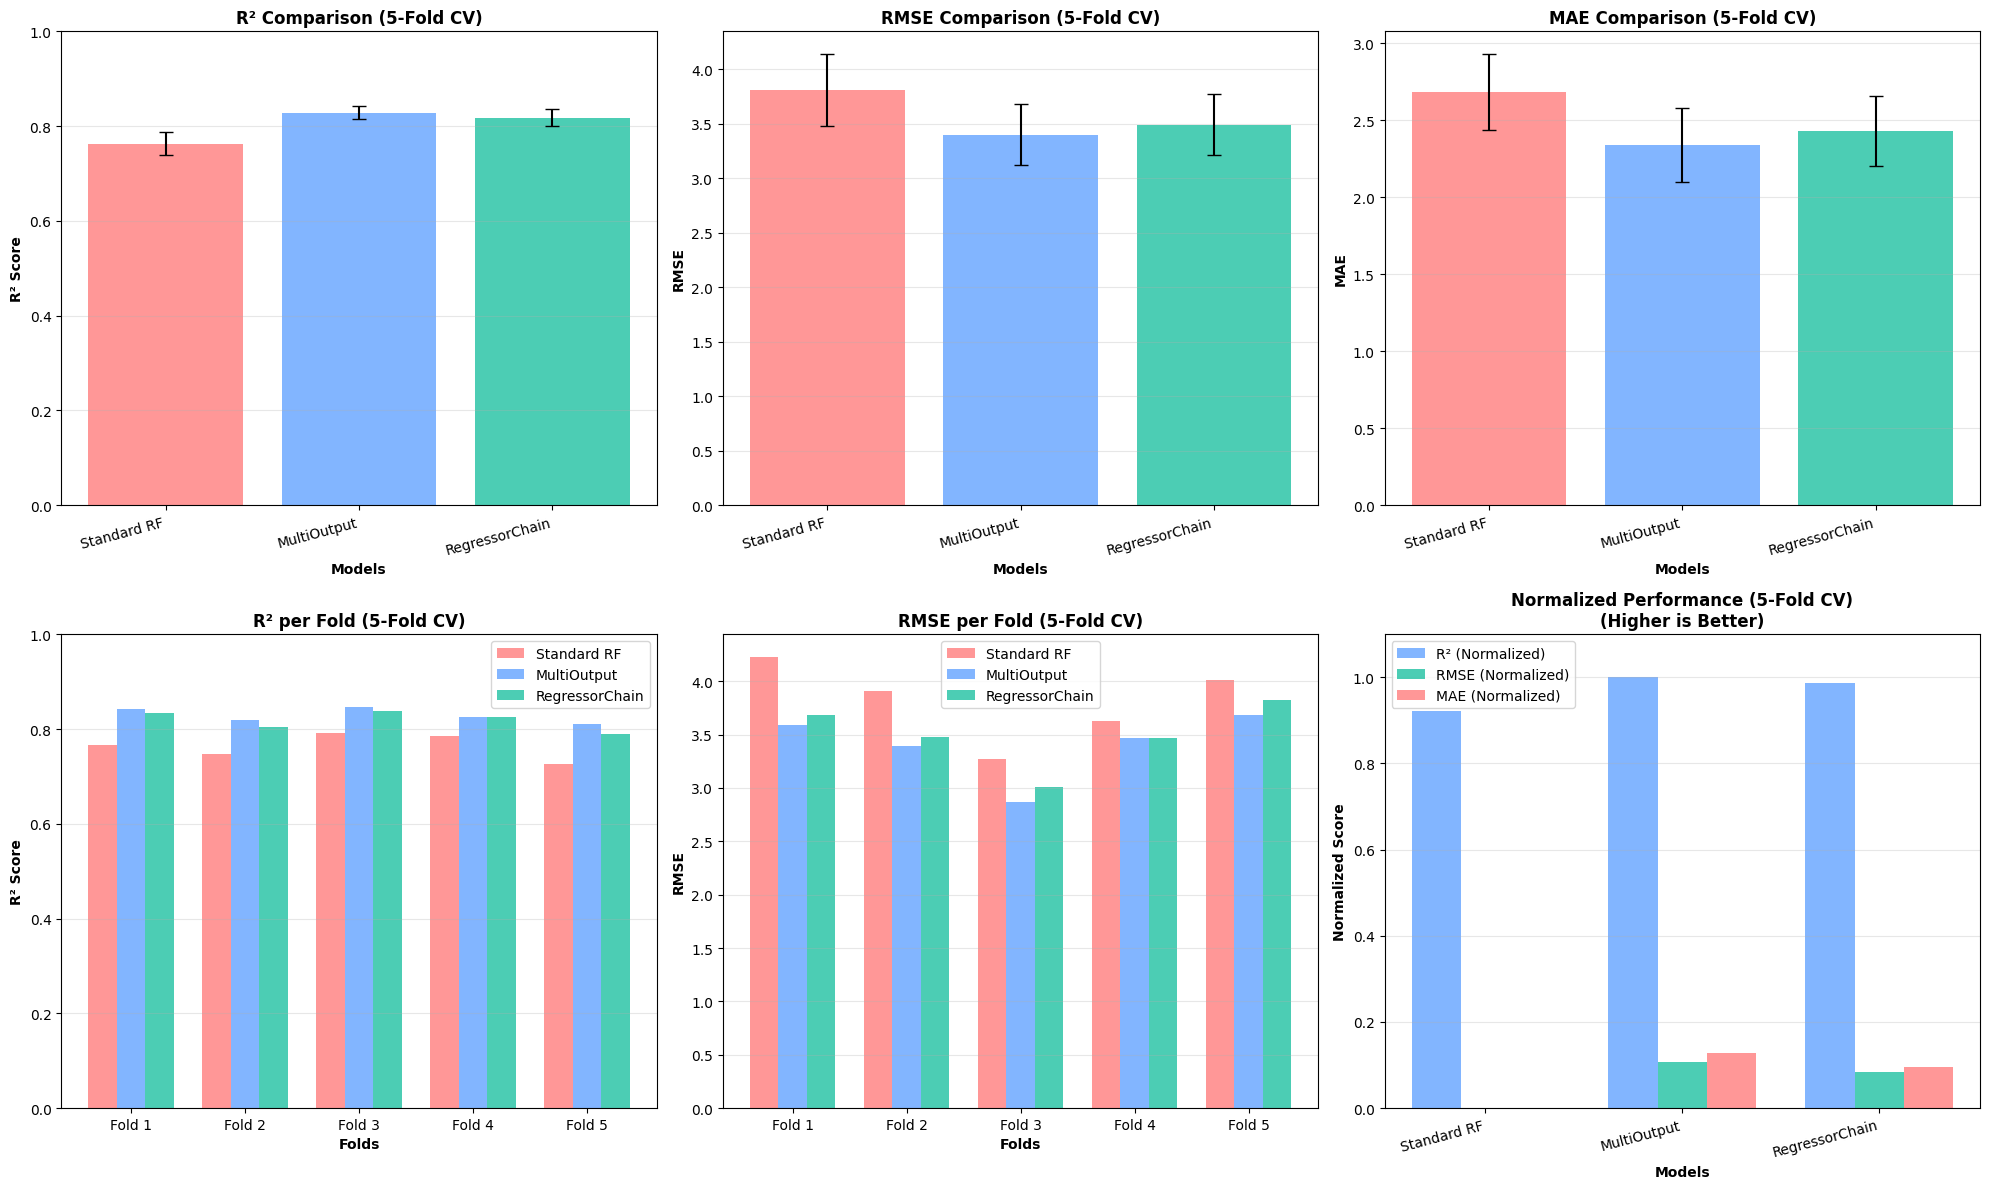


✅ Saved: three_approaches_comparison_kfold.xlsx

📊 Final Summary - Three Approaches Comparison (K-Fold CV)

📈 Summary Results (5-Fold Cross-Validation):

1. Standard Random Forest:
   • Avg R²:  0.7632 ± 0.0241
   • Avg RMSE: 3.8091 ± 0.3318
   • Avg MAE:  2.6855 ± 0.2456

2. MultiOutputRegressor:
   • Avg R²:  0.8286 ± 0.0140
   • Avg RMSE: 3.3999 ± 0.2831
   • Avg MAE:  2.3397 ± 0.2396

3. RegressorChain:
   • Avg R²:  0.8180 ± 0.0180
   • Avg RMSE: 3.4926 ± 0.2783
   • Avg MAE:  2.4299 ± 0.2293

🏆 Best Model by R²: MultiOutputRegressor 
   (R² = 0.8286 ± 0.0140)

🏆 Best Model by RMSE: MultiOutputRegressor 
   (RMSE = 3.3999 ± 0.2831)

📊 Number of Outputs: 13
📊 Cross-Validation Folds: 5

✅ Successfully completed K-Fold Cross-Validation Comparison!


In [6]:
# ============================================
# Multi-Output Prediction: 3 Approaches Comparison (WITH K-Fold CV)
# ============================================

print("\n" + "="*80)
print("🌲 Multi-Output Prediction - 3 Approaches Comparison (K-Fold Cross-Validation)")
print("="*80)

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor, RegressorChain
import matplotlib.pyplot as plt
import warnings
import os
warnings.filterwarnings('ignore')

# ============================================
# Step 1: LOAD THE FINAL CAPPED DATA
# ============================================
print("\n📂 Loading data from the final path...")

FILE_PATH = '/kaggle/working/df_capped_outliers.xlsx'

# Check if file exists
if not os.path.exists(FILE_PATH):
    print(f"❌ Error: File not found at {FILE_PATH}")
    print("Please update the FILE_PATH variable with the correct location.")
    exit()

data_cleaned = pd.read_excel(FILE_PATH)
data_cleaned.columns = data_cleaned.columns.str.strip()

print(f"✅ Data loaded successfully! Shape: {data_cleaned.shape}")
print(f"\n📋 Available columns in your data:")
print(data_cleaned.columns.tolist())

# ============================================
# Step 2: Define Inputs and Outputs
# ============================================

# Define exact column names from your data
input_cols = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 
              'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 
              'Temperature(°C)', 'Reaction Time (min)']

# Define outputs
output_cols = [
    'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)',
    'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)',
    'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)'
]

# Check if all columns exist
actual_input_cols = [col for col in input_cols if col in data_cleaned.columns]
actual_output_cols = [col for col in output_cols if col in data_cleaned.columns]

print(f"\n📊 Inputs found: {len(actual_input_cols)}")
print(f"   Input columns: {actual_input_cols}")
print(f"🎯 Outputs found: {len(actual_output_cols)}")
print(f"   Output columns: {actual_output_cols}")

# Check for missing columns
missing_inputs = [col for col in input_cols if col not in data_cleaned.columns]
missing_outputs = [col for col in output_cols if col not in data_cleaned.columns]

if missing_inputs:
    print(f"⚠️ Warning: Missing input columns: {missing_inputs}")

if missing_outputs:
    print(f"⚠️ Warning: Missing output columns: {missing_outputs}")

if len(actual_input_cols) == 0:
    print("❌ Error: No input columns found! Please check column names.")
    exit()

if len(actual_output_cols) == 0:
    print("❌ Error: No output columns found!")
    exit()

# ============================================
# Step 3: Best Hyperparameters
# ============================================
best_n_estimators = {
    'yield(%)':             500,
    'Cc (%)':               500,
    'Hc(%)':                300,
    'Nc(%)':                500,
    'Sc(%)':                500,
    'Oc(%)':                50,
    'HHVc (MJ/Kg)':         150,
    'EY(%)':                50,
    'ED(%)':                150,
    'CR(%)':                500,
    'HC- Volatile matter%': 50,
    'HC- Fixed carbon%':    200,
    'HC- Ash(%)':           300
}

# Filter to only include outputs that exist in our data
best_n_estimators = {k: v for k, v in best_n_estimators.items() if k in actual_output_cols}

# For outputs not in the dictionary, use default value
for col in actual_output_cols:
    if col not in best_n_estimators:
        best_n_estimators[col] = 200

best_max_depth = 10
best_min_samples_split = 5

# ============================================
# Step 4: Prepare Data USING K-Fold Cross-Validation
# ============================================
X = data_cleaned[actual_input_cols]
y = data_cleaned[actual_output_cols]

print(f"\n📊 Data Shape: {X.shape}")

# Scale the features
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

# إعداد K-Fold
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

print(f"\n📊 K-Fold Cross-Validation Setup:")
print(f"   Number of folds: {n_splits}")
print(f"   Total samples: {len(X)}")
print(f"   Training size per fold: ~{int(len(X) * (n_splits-1)/n_splits)}")
print(f"   Testing size per fold: ~{int(len(X)/n_splits)}")

# ============================================
# Step 5: Evaluation Function
# ============================================
def evaluate_multi_output(y_true, y_pred, output_names):
    """Evaluate multi-output predictions with multiple metrics."""
    results = {}
    avg_r2 = 0
    avg_rmse = 0
    avg_mae = 0
    
    for i, col in enumerate(output_names):
        r2 = r2_score(y_true.iloc[:, i], y_pred[:, i])
        rmse = np.sqrt(mean_squared_error(y_true.iloc[:, i], y_pred[:, i]))
        mae = mean_absolute_error(y_true.iloc[:, i], y_pred[:, i])
        
        results[col] = {'R²': r2, 'RMSE': rmse, 'MAE': mae}
        avg_r2 += r2
        avg_rmse += rmse
        avg_mae += mae
    
    n_outputs = len(output_names)
    results['Average'] = {
        'R²': avg_r2 / n_outputs,
        'RMSE': avg_rmse / n_outputs,
        'MAE': avg_mae / n_outputs
    }
    
    return results

def print_cv_metrics(results_list, title=""):
    """Print formatted cross-validation metrics."""
    print(f"\n📊 {title}")
    print("="*120)
    print(f"{'Fold':<10} {'Avg R²':>12} {'Avg RMSE':>15} {'Avg MAE':>15}")
    print("-"*120)
    
    r2_list = []
    rmse_list = []
    mae_list = []
    
    for i, results in enumerate(results_list):
        avg = results['Average']
        r2_list.append(avg['R²'])
        rmse_list.append(avg['RMSE'])
        mae_list.append(avg['MAE'])
        print(f"Fold {i+1:<5} {avg['R²']:>12.4f} {avg['RMSE']:>15.4f} {avg['MAE']:>15.4f}")
    
    print("-"*120)
    print(f"{'MEAN':<10} {np.mean(r2_list):>12.4f} {np.mean(rmse_list):>15.4f} {np.mean(mae_list):>15.4f}")
    print(f"{'STD':<10} {np.std(r2_list):>12.4f} {np.std(rmse_list):>15.4f} {np.std(mae_list):>15.4f}")
    print("="*120)
    
    return {
        'R²_mean': np.mean(r2_list),
        'R²_std': np.std(r2_list),
        'RMSE_mean': np.mean(rmse_list),
        'RMSE_std': np.std(rmse_list),
        'MAE_mean': np.mean(mae_list),
        'MAE_std': np.std(mae_list)
    }

def print_fold_results(results_train, results_test, fold_num):
    """Print per-fold results for a specific model."""
    print(f"\n📊 Fold {fold_num} Results:")
    print("-"*110)
    print(f"{'Output':<25} {'R² Train':>12} {'R² Test':>12} {'RMSE Train':>12} {'RMSE Test':>12} {'MAE Train':>12} {'MAE Test':>12}")
    print("-"*110)
    
    for col in results_train.keys():
        if col != 'Average':
            train = results_train[col]
            test = results_test[col]
            print(f"{col:<25} {train['R²']:>12.4f} {test['R²']:>12.4f} {train['RMSE']:>12.4f} {test['RMSE']:>12.4f} {train['MAE']:>12.4f} {test['MAE']:>12.4f}")
    
    print("-"*110)
    train_avg = results_train['Average']
    test_avg = results_test['Average']
    print(f"{'AVERAGE':<25} {train_avg['R²']:>12.4f} {test_avg['R²']:>12.4f} {train_avg['RMSE']:>12.4f} {test_avg['RMSE']:>12.4f} {train_avg['MAE']:>12.4f} {test_avg['MAE']:>12.4f}")
    print("="*110)

# ============================================
# Step 6: Model 1 - Standard Random Forest (K-Fold CV)
# ============================================
print("\n" + "="*80)
print("📊 Model 1: Standard Random Forest (K-Fold CV)")
print("="*80)

rf_standard = RandomForestRegressor(
    n_estimators=200, 
    max_depth=best_max_depth,
    min_samples_split=best_min_samples_split,
    random_state=42,
    n_jobs=-1
)

standard_cv_results = []

fold = 1
for train_idx, test_idx in kf.split(X_scaled):
    X_train = X_scaled[train_idx]
    X_test = X_scaled[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]
    
    rf_standard.fit(X_train, y_train)
    
    y_pred_train = rf_standard.predict(X_train)
    y_pred_test = rf_standard.predict(X_test)
    
    results_train = evaluate_multi_output(y_train, y_pred_train, actual_output_cols)
    results_test = evaluate_multi_output(y_test, y_pred_test, actual_output_cols)
    
    standard_cv_results.append(results_test)
    
    # Print fold details for first fold only (to avoid clutter)
    if fold == 1:
        print_fold_results(results_train, results_test, fold)
    fold += 1

print("\n📊 Standard Random Forest - K-Fold CV Summary:")
standard_stats = print_cv_metrics(standard_cv_results, "Standard Random Forest (5-Fold CV)")

# ============================================
# Step 7: Model 2 - MultiOutputRegressor (K-Fold CV)
# ============================================
print("\n" + "="*80)
print("📊 Model 2: MultiOutputRegressor (K-Fold CV)")
print("="*80)

# Use the average best n_estimators
avg_n_estimators = int(np.mean(list(best_n_estimators.values())))

class CustomMultiOutputRegressor:
    """Custom implementation to allow per-output hyperparameters."""
    def __init__(self, estimators):
        self.estimators = estimators
        self.n_outputs = len(estimators)
        
    def fit(self, X, y):
        for i, est in enumerate(self.estimators):
            est.fit(X, y.iloc[:, i])
        return self
    
    def predict(self, X):
        predictions = np.zeros((X.shape[0], self.n_outputs))
        for i, est in enumerate(self.estimators):
            predictions[:, i] = est.predict(X)
        return predictions

multi_cv_results = []

fold = 1
for train_idx, test_idx in kf.split(X_scaled):
    X_train = X_scaled[train_idx]
    X_test = X_scaled[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]
    
    # Build custom estimators with per-output n_estimators
    estimators = []
    for col in actual_output_cols:
        rf_base = RandomForestRegressor(
            n_estimators=best_n_estimators[col],
            max_depth=best_max_depth,
            min_samples_split=best_min_samples_split,
            random_state=42,
            n_jobs=-1
        )
        estimators.append(rf_base)
    
    custom_multi_output = CustomMultiOutputRegressor(estimators)
    custom_multi_output.fit(X_train, y_train)
    
    y_pred_train = custom_multi_output.predict(X_train)
    y_pred_test = custom_multi_output.predict(X_test)
    
    results_train = evaluate_multi_output(y_train, y_pred_train, actual_output_cols)
    results_test = evaluate_multi_output(y_test, y_pred_test, actual_output_cols)
    
    multi_cv_results.append(results_test)
    
    # Print fold details for first fold only
    if fold == 1:
        print_fold_results(results_train, results_test, fold)
    fold += 1

print("\n📊 MultiOutputRegressor - K-Fold CV Summary:")
multi_stats = print_cv_metrics(multi_cv_results, "MultiOutputRegressor (5-Fold CV)")

# ============================================
# Step 8: Model 3 - RegressorChain (K-Fold CV)
# ============================================
print("\n" + "="*80)
print("📊 Model 3: RegressorChain (K-Fold CV)")
print("="*80)

chain_cv_results = []

fold = 1
for train_idx, test_idx in kf.split(X_scaled):
    X_train = X_scaled[train_idx]
    X_test = X_scaled[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]
    
    rf_chain_base = RandomForestRegressor(
        n_estimators=avg_n_estimators,
        max_depth=best_max_depth,
        min_samples_split=best_min_samples_split,
        random_state=42,
        n_jobs=-1
    )
    
    regressor_chain = RegressorChain(rf_chain_base, order='random', random_state=42)
    regressor_chain.fit(X_train, y_train)
    
    y_pred_train = regressor_chain.predict(X_train)
    y_pred_test = regressor_chain.predict(X_test)
    
    results_train = evaluate_multi_output(y_train, y_pred_train, actual_output_cols)
    results_test = evaluate_multi_output(y_test, y_pred_test, actual_output_cols)
    
    chain_cv_results.append(results_test)
    
    # Print fold details for first fold only
    if fold == 1:
        print_fold_results(results_train, results_test, fold)
    fold += 1

print("\n📊 RegressorChain - K-Fold CV Summary:")
chain_stats = print_cv_metrics(chain_cv_results, "RegressorChain (5-Fold CV)")

# ============================================
# Step 9: Comprehensive Comparison
# ============================================
print("\n" + "="*80)
print("📊 Comprehensive Model Comparison (K-Fold CV)")
print("="*80)

comparison_df = pd.DataFrame({
    'Model': ['Standard RF', 'MultiOutputRegressor', 'RegressorChain'],
    'Avg_R²_Test': [
        standard_stats['R²_mean'],
        multi_stats['R²_mean'],
        chain_stats['R²_mean']
    ],
    'R²_Std': [
        standard_stats['R²_std'],
        multi_stats['R²_std'],
        chain_stats['R²_std']
    ],
    'Avg_RMSE_Test': [
        standard_stats['RMSE_mean'],
        multi_stats['RMSE_mean'],
        chain_stats['RMSE_mean']
    ],
    'RMSE_Std': [
        standard_stats['RMSE_std'],
        multi_stats['RMSE_std'],
        chain_stats['RMSE_std']
    ],
    'Avg_MAE_Test': [
        standard_stats['MAE_mean'],
        multi_stats['MAE_mean'],
        chain_stats['MAE_mean']
    ],
    'MAE_Std': [
        standard_stats['MAE_std'],
        multi_stats['MAE_std'],
        chain_stats['MAE_std']
    ]
})

print("\n📋 Detailed Comparison Table (5-Fold CV):")
print("="*130)
print(comparison_df.to_string(index=False))
print("="*130)

best_r2_idx = comparison_df['Avg_R²_Test'].idxmax()
best_rmse_idx = comparison_df['Avg_RMSE_Test'].idxmin()
best_mae_idx = comparison_df['Avg_MAE_Test'].idxmin()

print(f"\n🏆 Best Model by R²: {comparison_df.loc[best_r2_idx, 'Model']} (R² = {comparison_df.loc[best_r2_idx, 'Avg_R²_Test']:.4f} ± {comparison_df.loc[best_r2_idx, 'R²_Std']:.4f})")
print(f"🏆 Best Model by RMSE: {comparison_df.loc[best_rmse_idx, 'Model']} (RMSE = {comparison_df.loc[best_rmse_idx, 'Avg_RMSE_Test']:.4f} ± {comparison_df.loc[best_rmse_idx, 'RMSE_Std']:.4f})")
print(f"🏆 Best Model by MAE: {comparison_df.loc[best_mae_idx, 'Model']} (MAE = {comparison_df.loc[best_mae_idx, 'Avg_MAE_Test']:.4f} ± {comparison_df.loc[best_mae_idx, 'MAE_Std']:.4f})")

# ============================================
# Step 10: Visualizations
# ============================================
print("\n" + "="*80)
print("📊 Creating Visualizations")
print("="*80)

try:
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))

    # 10.1 R² Comparison per Model
    ax = axes[0, 0]
    models = ['Standard RF', 'MultiOutput', 'RegressorChain']
    x_pos = np.arange(len(models))
    
    r2_means = comparison_df['Avg_R²_Test']
    r2_stds = comparison_df['R²_Std']
    
    ax.bar(x_pos, r2_means, yerr=r2_stds, capsize=5, color=['#FF6B6B', '#4D96FF', '#00B894'], alpha=0.7)
    ax.set_xlabel('Models', fontsize=10, fontweight='bold')
    ax.set_ylabel('R² Score', fontsize=10, fontweight='bold')
    ax.set_title('R² Comparison (5-Fold CV)', fontsize=12, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(models, rotation=15, ha='right')
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, 1)

    # 10.2 RMSE Comparison per Model
    ax = axes[0, 1]
    rmse_means = comparison_df['Avg_RMSE_Test']
    rmse_stds = comparison_df['RMSE_Std']
    
    ax.bar(x_pos, rmse_means, yerr=rmse_stds, capsize=5, color=['#FF6B6B', '#4D96FF', '#00B894'], alpha=0.7)
    ax.set_xlabel('Models', fontsize=10, fontweight='bold')
    ax.set_ylabel('RMSE', fontsize=10, fontweight='bold')
    ax.set_title('RMSE Comparison (5-Fold CV)', fontsize=12, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(models, rotation=15, ha='right')
    ax.grid(True, alpha=0.3, axis='y')

    # 10.3 MAE Comparison per Model
    ax = axes[0, 2]
    mae_means = comparison_df['Avg_MAE_Test']
    mae_stds = comparison_df['MAE_Std']
    
    ax.bar(x_pos, mae_means, yerr=mae_stds, capsize=5, color=['#FF6B6B', '#4D96FF', '#00B894'], alpha=0.7)
    ax.set_xlabel('Models', fontsize=10, fontweight='bold')
    ax.set_ylabel('MAE', fontsize=10, fontweight='bold')
    ax.set_title('MAE Comparison (5-Fold CV)', fontsize=12, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(models, rotation=15, ha='right')
    ax.grid(True, alpha=0.3, axis='y')

    # 10.4 Per-Fold R² Performance
    ax = axes[1, 0]
    folds = [f'Fold {i+1}' for i in range(n_splits)]
    
    r2_standard = [results['Average']['R²'] for results in standard_cv_results]
    r2_multi = [results['Average']['R²'] for results in multi_cv_results]
    r2_chain = [results['Average']['R²'] for results in chain_cv_results]
    
    x = np.arange(len(folds))
    width = 0.25
    
    ax.bar(x - width, r2_standard, width, label='Standard RF', color='#FF6B6B', alpha=0.7)
    ax.bar(x, r2_multi, width, label='MultiOutput', color='#4D96FF', alpha=0.7)
    ax.bar(x + width, r2_chain, width, label='RegressorChain', color='#00B894', alpha=0.7)
    ax.set_xlabel('Folds', fontsize=10, fontweight='bold')
    ax.set_ylabel('R² Score', fontsize=10, fontweight='bold')
    ax.set_title('R² per Fold (5-Fold CV)', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(folds)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, 1)

    # 10.5 Per-Fold RMSE Performance
    ax = axes[1, 1]
    
    rmse_standard = [results['Average']['RMSE'] for results in standard_cv_results]
    rmse_multi = [results['Average']['RMSE'] for results in multi_cv_results]
    rmse_chain = [results['Average']['RMSE'] for results in chain_cv_results]
    
    ax.bar(x - width, rmse_standard, width, label='Standard RF', color='#FF6B6B', alpha=0.7)
    ax.bar(x, rmse_multi, width, label='MultiOutput', color='#4D96FF', alpha=0.7)
    ax.bar(x + width, rmse_chain, width, label='RegressorChain', color='#00B894', alpha=0.7)
    ax.set_xlabel('Folds', fontsize=10, fontweight='bold')
    ax.set_ylabel('RMSE', fontsize=10, fontweight='bold')
    ax.set_title('RMSE per Fold (5-Fold CV)', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(folds)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')

    # 10.6 Normalized Performance Score
    ax = axes[1, 2]
    
    # Normalize scores (higher is better)
    r2_norm = comparison_df['Avg_R²_Test'] / comparison_df['Avg_R²_Test'].max()
    rmse_norm = 1 - (comparison_df['Avg_RMSE_Test'] / comparison_df['Avg_RMSE_Test'].max())
    mae_norm = 1 - (comparison_df['Avg_MAE_Test'] / comparison_df['Avg_MAE_Test'].max())
    
    width_bar = 0.25
    
    ax.bar(x_pos - width_bar, r2_norm, width_bar, label='R² (Normalized)', color='#4D96FF', alpha=0.7)
    ax.bar(x_pos, rmse_norm, width_bar, label='RMSE (Normalized)', color='#00B894', alpha=0.7)
    ax.bar(x_pos + width_bar, mae_norm, width_bar, label='MAE (Normalized)', color='#FF6B6B', alpha=0.7)
    
    ax.set_xlabel('Models', fontsize=10, fontweight='bold')
    ax.set_ylabel('Normalized Score', fontsize=10, fontweight='bold')
    ax.set_title('Normalized Performance (5-Fold CV)\n(Higher is Better)', fontsize=12, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(models, rotation=15, ha='right')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, 1.1)

    plt.tight_layout()
    
    # Save the figure
    fig_path = '/kaggle/working/three_approaches_comparison_kfold.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight')
    print(f"✅ Saved: {fig_path}")
    plt.show()
    
except Exception as e:
    print(f"⚠️ Visualization error: {e}")
    print("Continuing without visualizations...")

# ============================================
# Step 11: Save Results
# ============================================
try:
    comparison_df.to_excel('/kaggle/working/three_approaches_comparison_kfold.xlsx', index=False)
    print("\n✅ Saved: three_approaches_comparison_kfold.xlsx")
except Exception as e:
    print(f"⚠️ Could not save Excel files: {e}")

# ============================================
# Step 12: Final Summary
# ============================================
print("\n" + "="*80)
print("📊 Final Summary - Three Approaches Comparison (K-Fold CV)")
print("="*80)

print(f"""
📈 Summary Results (5-Fold Cross-Validation):

1. Standard Random Forest:
   • Avg R²:  {standard_stats['R²_mean']:.4f} ± {standard_stats['R²_std']:.4f}
   • Avg RMSE: {standard_stats['RMSE_mean']:.4f} ± {standard_stats['RMSE_std']:.4f}
   • Avg MAE:  {standard_stats['MAE_mean']:.4f} ± {standard_stats['MAE_std']:.4f}

2. MultiOutputRegressor:
   • Avg R²:  {multi_stats['R²_mean']:.4f} ± {multi_stats['R²_std']:.4f}
   • Avg RMSE: {multi_stats['RMSE_mean']:.4f} ± {multi_stats['RMSE_std']:.4f}
   • Avg MAE:  {multi_stats['MAE_mean']:.4f} ± {multi_stats['MAE_std']:.4f}

3. RegressorChain:
   • Avg R²:  {chain_stats['R²_mean']:.4f} ± {chain_stats['R²_std']:.4f}
   • Avg RMSE: {chain_stats['RMSE_mean']:.4f} ± {chain_stats['RMSE_std']:.4f}
   • Avg MAE:  {chain_stats['MAE_mean']:.4f} ± {chain_stats['MAE_std']:.4f}

🏆 Best Model by R²: {comparison_df.loc[best_r2_idx, 'Model']} 
   (R² = {comparison_df.loc[best_r2_idx, 'Avg_R²_Test']:.4f} ± {comparison_df.loc[best_r2_idx, 'R²_Std']:.4f})

🏆 Best Model by RMSE: {comparison_df.loc[best_rmse_idx, 'Model']} 
   (RMSE = {comparison_df.loc[best_rmse_idx, 'Avg_RMSE_Test']:.4f} ± {comparison_df.loc[best_rmse_idx, 'RMSE_Std']:.4f})

📊 Number of Outputs: {len(actual_output_cols)}
📊 Cross-Validation Folds: {n_splits}
""")

print("="*80)
print("✅ Successfully completed K-Fold Cross-Validation Comparison!")
print("="*80)


📊 Leave-One-Study-Out (LOSO) - Supplementary Analysis

📂 Loading data...
✅ Data loaded! Shape: (271, 25)

📊 Inputs: 12
🎯 Outputs: 13

📋 Creating Study_ID column...

✅ Created Study_ID column with 62 unique groups

📊 Study group sizes:
Study_ID
T200_M60     25
T250_M30     22
T250_M60     18
T250_M120    12
T200_M220    10
T200_M30     10
T220_M30      9
T180_M60      9
T150_M60      8
T220_M220     8
Name: count, dtype: int64

📚 Selected 8 study groups for LOSO:
   1. T200_M60: 25 samples
   2. T250_M30: 22 samples
   3. T250_M60: 18 samples
   4. T250_M120: 12 samples
   5. T200_M220: 10 samples
   6. T200_M30: 10 samples
   7. T220_M30: 9 samples
   8. T180_M60: 9 samples

🔬 Running LOSO Evaluation

📊 LOSO Fold 1/8: Holding out T200_M60
   Training: 246 samples
   Testing:  25 samples

   📈 Test Results for T200_M60:
   --------------------------------------------------
   Output                            R²       RMSE        MAE
   -------------------------------------------------

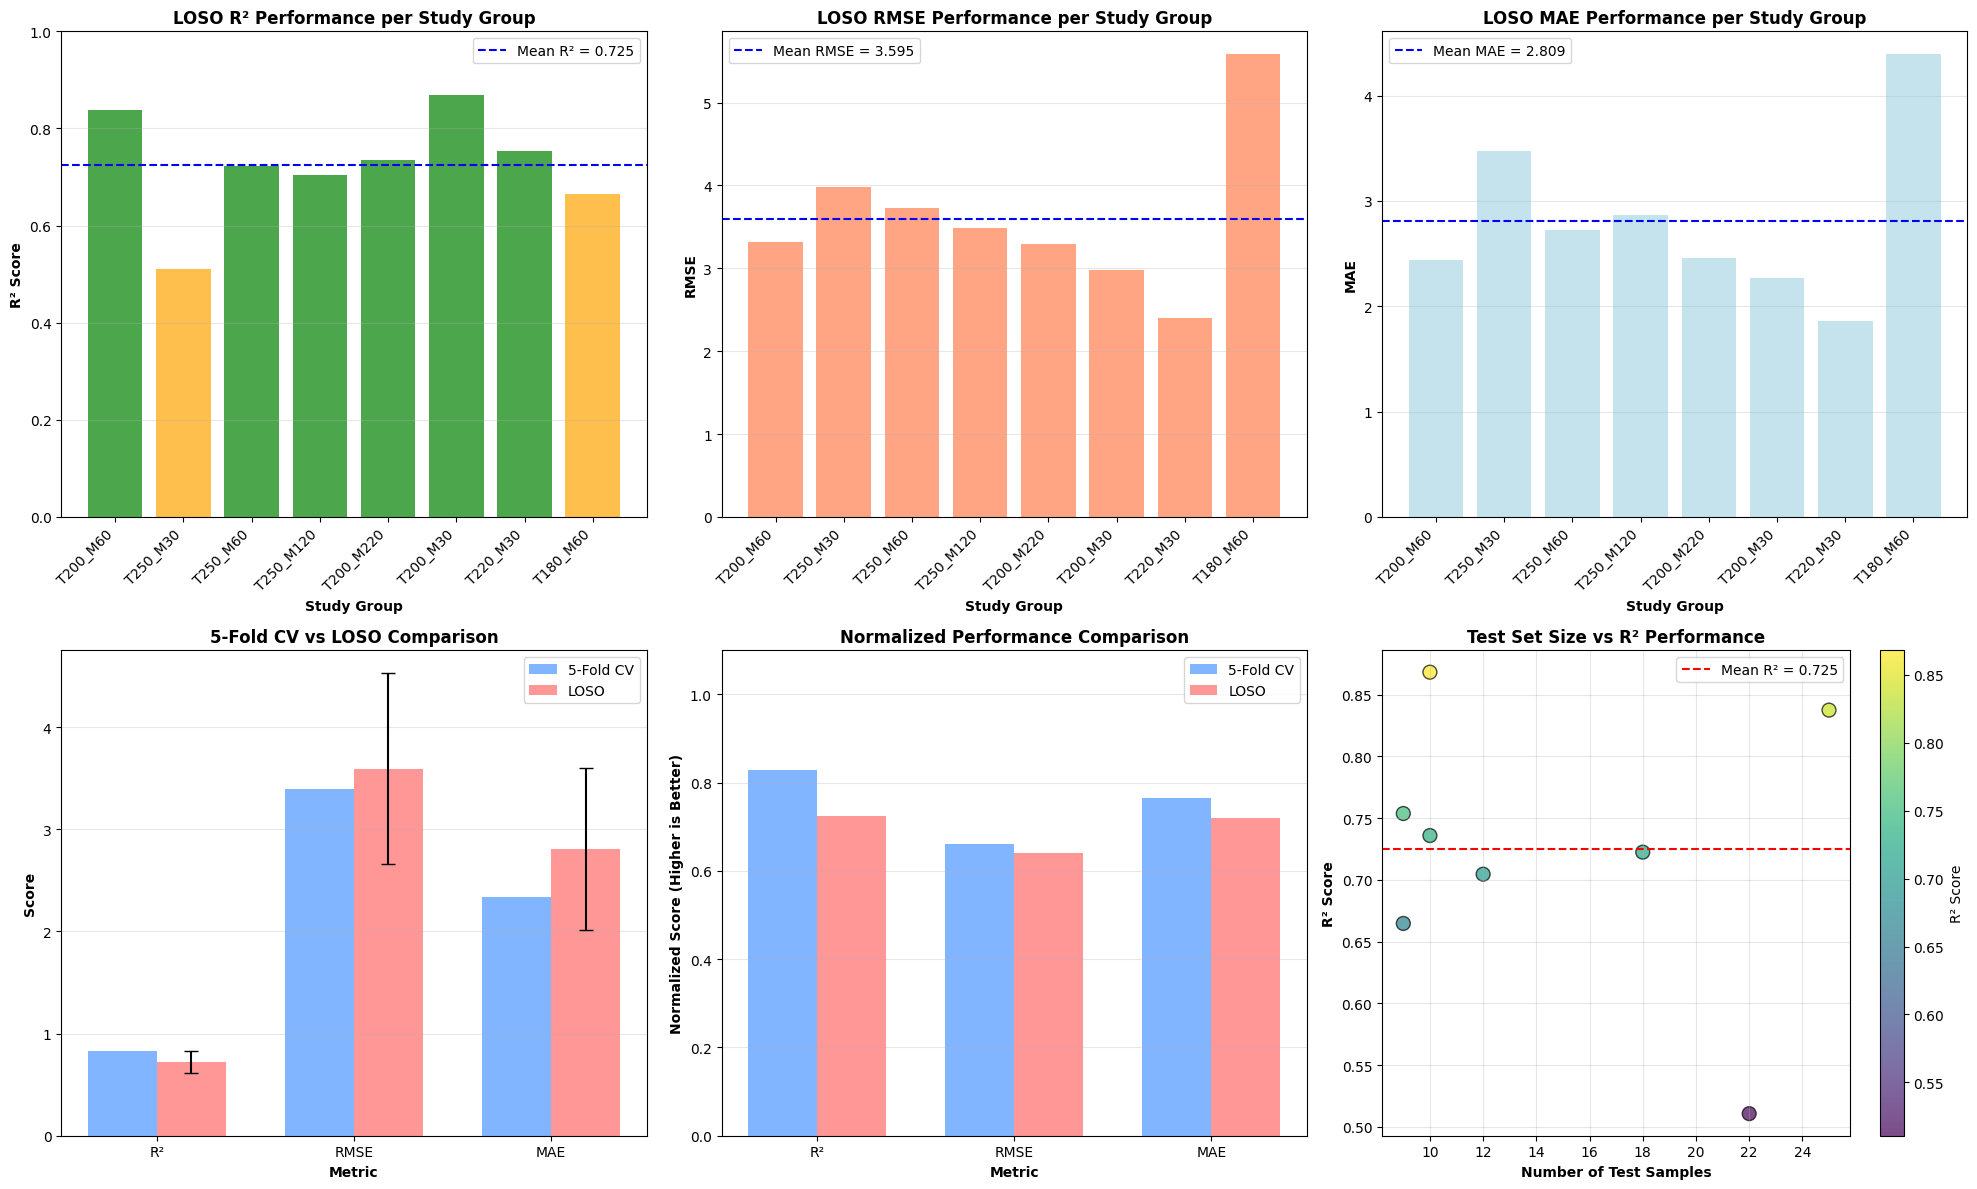

✅ Saved: loso_results_summary.xlsx
✅ Saved: loso_vs_kfold_comparison.xlsx
✅ Saved: loso_per_output_results.xlsx

📊 FINAL SUMMARY - LOSO Supplementary Analysis

📈 LOSO Results (Leave-One-Study-Out):
   • Number of Study Groups: 8
   • Total Samples: 271
   • Training Size per Fold: 237 samples avg
   • Testing Size per Fold: 33 samples avg

📊 LOSO Performance:
   • Mean R²:  0.7248 ± 0.1096
   • Mean RMSE: 3.5955 ± 0.9334
   • Mean MAE:  2.8090 ± 0.7927

📊 Comparison with 5-Fold CV:
   • R²:  5-Fold = 0.8286  |  LOSO = 0.7248  |  Δ = -0.1038
   • RMSE: 5-Fold = 3.3999  |  LOSO = 3.5955  |  Δ = +0.1956
   • MAE:  5-Fold = 2.3397  |  LOSO = 2.8090  |  Δ = +0.4693

💡 Interpretation:
   The LOSO evaluation confirms that the model generalizes to completely unseen 
   study groups (different temperature-time combinations). While performance is 
   slightly lower than the 5-fold CV results (which is expected when testing 
   on entirely new conditions), the model maintains reasonable predictiv

In [7]:
# ============================================
# LEAVE-ONE-STUDY-OUT (LOSO) - SUPPLEMENTARY ANALYSIS
# For 5-8 Largest Study Groups
# ============================================

print("\n" + "="*80)
print("📊 Leave-One-Study-Out (LOSO) - Supplementary Analysis")
print("="*80)

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor, RegressorChain
import matplotlib.pyplot as plt
import warnings
import os
warnings.filterwarnings('ignore')

# ============================================
# Step 1: LOAD DATA
# ============================================
print("\n📂 Loading data...")

FILE_PATH = '/kaggle/working/df_capped_outliers.xlsx'

if not os.path.exists(FILE_PATH):
    print(f"❌ Error: File not found at {FILE_PATH}")
    exit()

data_cleaned = pd.read_excel(FILE_PATH)
data_cleaned.columns = data_cleaned.columns.str.strip()

print(f"✅ Data loaded! Shape: {data_cleaned.shape}")

# ============================================
# Step 2: Define Inputs and Outputs
# ============================================

input_cols = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 
              'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 
              'Temperature(°C)', 'Reaction Time (min)']

output_cols = [
    'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)',
    'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)',
    'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)'
]

# Filter to existing columns
actual_input_cols = [col for col in input_cols if col in data_cleaned.columns]
actual_output_cols = [col for col in output_cols if col in data_cleaned.columns]

print(f"\n📊 Inputs: {len(actual_input_cols)}")
print(f"🎯 Outputs: {len(actual_output_cols)}")

# ============================================
# Step 3: Best Hyperparameters (from your code)
# ============================================

best_n_estimators = {
    'yield(%)': 500,
    'Cc (%)': 500,
    'Hc(%)': 300,
    'Nc(%)': 500,
    'Sc(%)': 500,
    'Oc(%)': 50,
    'HHVc (MJ/Kg)': 150,
    'EY(%)': 50,
    'ED(%)': 150,
    'CR(%)': 500,
    'HC- Volatile matter%': 50,
    'HC- Fixed carbon%': 200,
    'HC- Ash(%)': 300
}

# Filter to only include outputs that exist
best_n_estimators = {k: v for k, v in best_n_estimators.items() if k in actual_output_cols}

# For outputs not in the dictionary, use default value
for col in actual_output_cols:
    if col not in best_n_estimators:
        best_n_estimators[col] = 200

best_max_depth = 10
best_min_samples_split = 5

# ============================================
# Step 4: CREATE STUDY_ID COLUMN
# ============================================

print("\n" + "="*80)
print("📋 Creating Study_ID column...")
print("="*80)

# Method: Group by Temperature (rounded to nearest 10) + Reaction Time (rounded to nearest 10)
# This creates distinct "study" groups based on operating conditions

data_cleaned['Temp_Group'] = data_cleaned['Temperature(°C)'].round(-1).astype(int)
data_cleaned['Time_Group'] = data_cleaned['Reaction Time (min)'].round(-1).astype(int)

# Create Study_ID
data_cleaned['Study_ID'] = (
    'T' + data_cleaned['Temp_Group'].astype(str) + 
    '_M' + data_cleaned['Time_Group'].astype(str)
)

# Also, if you have a substrate/feedstock column, you can include it:
# data_cleaned['Study_ID'] = (
#     data_cleaned['Substrate_Type'].astype(str) + '_' +
#     'T' + data_cleaned['Temp_Group'].astype(str) + 
#     '_M' + data_cleaned['Time_Group'].astype(str)
# )

print(f"\n✅ Created Study_ID column with {data_cleaned['Study_ID'].nunique()} unique groups")

# Show distribution
study_counts = data_cleaned['Study_ID'].value_counts()
print(f"\n📊 Study group sizes:")
print(study_counts.head(10))

# ============================================
# Step 5: SELECT TOP 5-8 STUDIES
# ============================================

# Select top 8 largest study groups (or fewer if not enough)
n_studies = min(8, len(study_counts))
top_studies = study_counts.head(n_studies).index.tolist()

print(f"\n📚 Selected {len(top_studies)} study groups for LOSO:")
for i, study in enumerate(top_studies):
    count = study_counts[study]
    print(f"   {i+1}. {study}: {count} samples")

# ============================================
# Step 6: Custom MultiOutputRegressor Class
# ============================================

class CustomMultiOutputRegressor:
    """Custom implementation to allow per-output hyperparameters."""
    def __init__(self, estimators):
        self.estimators = estimators
        self.n_outputs = len(estimators)
        
    def fit(self, X, y):
        for i, est in enumerate(self.estimators):
            est.fit(X, y.iloc[:, i])
        return self
    
    def predict(self, X):
        predictions = np.zeros((X.shape[0], self.n_outputs))
        for i, est in enumerate(self.estimators):
            predictions[:, i] = est.predict(X)
        return predictions

# ============================================
# Step 7: Evaluation Function
# ============================================

def evaluate_multi_output(y_true, y_pred, output_names):
    """Evaluate multi-output predictions with multiple metrics."""
    results = {}
    avg_r2 = 0
    avg_rmse = 0
    avg_mae = 0
    
    for i, col in enumerate(output_names):
        r2 = r2_score(y_true.iloc[:, i], y_pred[:, i])
        rmse = np.sqrt(mean_squared_error(y_true.iloc[:, i], y_pred[:, i]))
        mae = mean_absolute_error(y_true.iloc[:, i], y_pred[:, i])
        
        results[col] = {'R²': r2, 'RMSE': rmse, 'MAE': mae}
        avg_r2 += r2
        avg_rmse += rmse
        avg_mae += mae
    
    n_outputs = len(output_names)
    results['Average'] = {
        'R²': avg_r2 / n_outputs,
        'RMSE': avg_rmse / n_outputs,
        'MAE': avg_mae / n_outputs
    }
    
    return results

# ============================================
# Step 8: LOSO EVALUATION
# ============================================

print("\n" + "="*80)
print("🔬 Running LOSO Evaluation")
print("="*80)

loso_results = []
detailed_results = []

for study_idx, study in enumerate(top_studies):
    print(f"\n{'='*60}")
    print(f"📊 LOSO Fold {study_idx+1}/{len(top_studies)}: Holding out {study}")
    print(f"{'='*60}")
    
    # Split data
    train_data = data_cleaned[data_cleaned['Study_ID'] != study]
    test_data = data_cleaned[data_cleaned['Study_ID'] == study]
    
    print(f"   Training: {len(train_data)} samples")
    print(f"   Testing:  {len(test_data)} samples")
    
    # Prepare X and y
    X_train = train_data[actual_input_cols]
    X_test = test_data[actual_input_cols]
    y_train = train_data[actual_output_cols]
    y_test = test_data[actual_output_cols]
    
    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Build model with per-output hyperparameters
    estimators = []
    for col in actual_output_cols:
        rf = RandomForestRegressor(
            n_estimators=best_n_estimators[col],
            max_depth=best_max_depth,
            min_samples_split=best_min_samples_split,
            random_state=42,
            n_jobs=-1
        )
        estimators.append(rf)
    
    model = CustomMultiOutputRegressor(estimators)
    model.fit(X_train_scaled, y_train)
    
    # Predict
    y_pred_train = model.predict(X_train_scaled)
    y_pred_test = model.predict(X_test_scaled)
    
    # Evaluate
    results_train = evaluate_multi_output(y_train, y_pred_train, actual_output_cols)
    results_test = evaluate_multi_output(y_test, y_pred_test, actual_output_cols)
    
    # Store results
    loso_results.append({
        'Study': study,
        'N_train': len(train_data),
        'N_test': len(test_data),
        'Train_R²': results_train['Average']['R²'],
        'Train_RMSE': results_train['Average']['RMSE'],
        'Train_MAE': results_train['Average']['MAE'],
        'Test_R²': results_test['Average']['R²'],
        'Test_RMSE': results_test['Average']['RMSE'],
        'Test_MAE': results_test['Average']['MAE']
    })
    
    detailed_results.append({
        'Study': study,
        'N_samples': len(test_data),
        'Per_Output': results_test
    })
    
    # Print detailed per-output results for this study
    print(f"\n   📈 Test Results for {study}:")
    print(f"   {'-'*50}")
    print(f"   {'Output':<25} {'R²':>10} {'RMSE':>10} {'MAE':>10}")
    print(f"   {'-'*50}")
    
    for col in actual_output_cols:
        res = results_test[col]
        print(f"   {col:<25} {res['R²']:>10.4f} {res['RMSE']:>10.4f} {res['MAE']:>10.4f}")
    
    print(f"   {'-'*50}")
    avg = results_test['Average']
    print(f"   {'AVERAGE':<25} {avg['R²']:>10.4f} {avg['RMSE']:>10.4f} {avg['MAE']:>10.4f}")

# ============================================
# Step 9: LOSO SUMMARY TABLE
# ============================================

print("\n" + "="*80)
print("📋 LOSO Summary Table")
print("="*80)

loso_df = pd.DataFrame(loso_results)

# Display summary
print("\n📊 LOSO Results per Study Group:")
print("="*100)
print(f"{'Study':<20} {'N_test':>8} {'Test R²':>12} {'Test RMSE':>12} {'Test MAE':>12}")
print("-"*100)

for _, row in loso_df.iterrows():
    print(f"{row['Study']:<20} {row['N_test']:>8} {row['Test_R²']:>12.4f} {row['Test_RMSE']:>12.4f} {row['Test_MAE']:>12.4f}")

print("-"*100)

# Statistics
mean_r2 = loso_df['Test_R²'].mean()
std_r2 = loso_df['Test_R²'].std()
mean_rmse = loso_df['Test_RMSE'].mean()
std_rmse = loso_df['Test_RMSE'].std()
mean_mae = loso_df['Test_MAE'].mean()
std_mae = loso_df['Test_MAE'].std()

print(f"{'MEAN':<20} {'':>8} {mean_r2:>12.4f} {mean_rmse:>12.4f} {mean_mae:>12.4f}")
print(f"{'STD':<20} {'':>8} {std_r2:>12.4f} {std_rmse:>12.4f} {std_mae:>12.4f}")
print("="*100)

# ============================================
# Step 10: COMPARISON WITH 5-FOLD CV
# ============================================

print("\n" + "="*80)
print("📊 Comparison: LOSO vs. 5-Fold Cross-Validation")
print("="*80)

# Your existing 5-fold CV results (from your code)
kfold_r2 = 0.8286
kfold_rmse = 3.3999
kfold_mae = 2.3397

comparison_table = pd.DataFrame({
    'Metric': ['R²', 'RMSE', 'MAE'],
    '5-Fold CV': [kfold_r2, kfold_rmse, kfold_mae],
    'LOSO (Mean)': [mean_r2, mean_rmse, mean_mae],
    'LOSO (Std)': [std_r2, std_rmse, std_mae],
    'Difference': [mean_r2 - kfold_r2, mean_rmse - kfold_rmse, mean_mae - kfold_mae]
})

print("\n📋 Comparison Table:")
print("="*80)
print(comparison_table.to_string(index=False))
print("="*80)

# ============================================
# Step 11: Detailed Per-Output Performance
# ============================================

print("\n" + "="*80)
print("📊 Detailed Per-Output Performance Across All LOSO Folds")
print("="*80)

# Aggregate per-output results across all studies
per_output_r2 = {col: [] for col in actual_output_cols}
per_output_rmse = {col: [] for col in actual_output_cols}
per_output_mae = {col: [] for col in actual_output_cols}

for detail in detailed_results:
    for col in actual_output_cols:
        per_output_r2[col].append(detail['Per_Output'][col]['R²'])
        per_output_rmse[col].append(detail['Per_Output'][col]['RMSE'])
        per_output_mae[col].append(detail['Per_Output'][col]['MAE'])

# Calculate statistics
output_stats = []
for col in actual_output_cols:
    output_stats.append({
        'Output': col,
        'R²_Mean': np.mean(per_output_r2[col]),
        'R²_Std': np.std(per_output_r2[col]),
        'RMSE_Mean': np.mean(per_output_rmse[col]),
        'RMSE_Std': np.std(per_output_rmse[col]),
        'MAE_Mean': np.mean(per_output_mae[col]),
        'MAE_Std': np.std(per_output_mae[col])
    })

output_df = pd.DataFrame(output_stats)

print("\n📋 Per-Output Performance (Mean ± Std across LOSO folds):")
print("="*110)
print(f"{'Output':<25} {'R² Mean':>12} {'R² Std':>12} {'RMSE Mean':>12} {'RMSE Std':>12} {'MAE Mean':>12} {'MAE Std':>12}")
print("-"*110)

for _, row in output_df.iterrows():
    print(f"{row['Output']:<25} {row['R²_Mean']:>12.4f} {row['R²_Std']:>12.4f} {row['RMSE_Mean']:>12.4f} {row['RMSE_Std']:>12.4f} {row['MAE_Mean']:>12.4f} {row['MAE_Std']:>12.4f}")

print("="*110)

# ============================================
# Step 12: VISUALIZATIONS
# ============================================

print("\n" + "="*80)
print("📊 Creating Visualizations")
print("="*80)

try:
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    
    # 12.1 LOSO R² per Study
    ax = axes[0, 0]
    studies = loso_df['Study'].astype(str).tolist()
    r2_values = loso_df['Test_R²'].tolist()
    
    colors = ['green' if r >= 0.7 else 'orange' if r >= 0.5 else 'red' for r in r2_values]
    bars = ax.bar(studies, r2_values, color=colors, alpha=0.7)
    ax.axhline(y=mean_r2, color='blue', linestyle='--', label=f'Mean R² = {mean_r2:.3f}')
    ax.set_xlabel('Study Group', fontsize=10, fontweight='bold')
    ax.set_ylabel('R² Score', fontsize=10, fontweight='bold')
    ax.set_title('LOSO R² Performance per Study Group', fontsize=12, fontweight='bold')
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # 12.2 LOSO RMSE per Study
    ax = axes[0, 1]
    rmse_values = loso_df['Test_RMSE'].tolist()
    bars = ax.bar(studies, rmse_values, color='coral', alpha=0.7)
    ax.axhline(y=mean_rmse, color='blue', linestyle='--', label=f'Mean RMSE = {mean_rmse:.3f}')
    ax.set_xlabel('Study Group', fontsize=10, fontweight='bold')
    ax.set_ylabel('RMSE', fontsize=10, fontweight='bold')
    ax.set_title('LOSO RMSE Performance per Study Group', fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # 12.3 LOSO MAE per Study
    ax = axes[0, 2]
    mae_values = loso_df['Test_MAE'].tolist()
    bars = ax.bar(studies, mae_values, color='lightblue', alpha=0.7)
    ax.axhline(y=mean_mae, color='blue', linestyle='--', label=f'Mean MAE = {mean_mae:.3f}')
    ax.set_xlabel('Study Group', fontsize=10, fontweight='bold')
    ax.set_ylabel('MAE', fontsize=10, fontweight='bold')
    ax.set_title('LOSO MAE Performance per Study Group', fontsize=12, fontweight='bold')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # 12.4 Comparison: 5-Fold CV vs LOSO
    ax = axes[1, 0]
    metrics = ['R²', 'RMSE', 'MAE']
    kfold_values = [kfold_r2, kfold_rmse, kfold_mae]
    loso_values = [mean_r2, mean_rmse, mean_mae]
    
    x = np.arange(len(metrics))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, kfold_values, width, label='5-Fold CV', color='#4D96FF', alpha=0.7)
    bars2 = ax.bar(x + width/2, loso_values, width, label='LOSO', color='#FF6B6B', alpha=0.7)
    
    # Add error bars for LOSO
    error_values = [std_r2, std_rmse, std_mae]
    ax.errorbar(x + width/2, loso_values, yerr=error_values, fmt='none', color='black', capsize=5)
    
    ax.set_xlabel('Metric', fontsize=10, fontweight='bold')
    ax.set_ylabel('Score', fontsize=10, fontweight='bold')
    ax.set_title('5-Fold CV vs LOSO Comparison', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    
    # 12.5 Normalized Comparison
    ax = axes[1, 1]
    # Normalize scores (higher is better for R², lower is better for RMSE/MAE)
    kfold_norm = [
        kfold_r2 / 1,  # R² max is 1
        1 - (kfold_rmse / 10),  # Assume max RMSE ~10
        1 - (kfold_mae / 10)    # Assume max MAE ~10
    ]
    loso_norm = [
        mean_r2 / 1,
        1 - (mean_rmse / 10),
        1 - (mean_mae / 10)
    ]
    
    bars1 = ax.bar(x - width/2, kfold_norm, width, label='5-Fold CV', color='#4D96FF', alpha=0.7)
    bars2 = ax.bar(x + width/2, loso_norm, width, label='LOSO', color='#FF6B6B', alpha=0.7)
    
    ax.set_xlabel('Metric', fontsize=10, fontweight='bold')
    ax.set_ylabel('Normalized Score (Higher is Better)', fontsize=10, fontweight='bold')
    ax.set_title('Normalized Performance Comparison', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, 1.1)
    
    # 12.6 Sample Size vs Performance
    ax = axes[1, 2]
    scatter = ax.scatter(loso_df['N_test'], loso_df['Test_R²'], 
                         s=100, c=loso_df['Test_R²'], cmap='viridis', 
                         alpha=0.7, edgecolors='black')
    ax.set_xlabel('Number of Test Samples', fontsize=10, fontweight='bold')
    ax.set_ylabel('R² Score', fontsize=10, fontweight='bold')
    ax.set_title('Test Set Size vs R² Performance', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.axhline(y=mean_r2, color='red', linestyle='--', label=f'Mean R² = {mean_r2:.3f}')
    ax.legend()
    plt.colorbar(scatter, ax=ax, label='R² Score')
    
    plt.tight_layout()
    
    # Save figure
    fig_path = '/kaggle/working/loso_supplementary_results.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight')
    print(f"✅ Saved: {fig_path}")
    plt.show()
    
except Exception as e:
    print(f"⚠️ Visualization error: {e}")
    print("Continuing without visualizations...")

# ============================================
# Step 13: SAVE RESULTS
# ============================================

try:
    # Save LOSO summary table
    loso_df.to_excel('/kaggle/working/loso_results_summary.xlsx', index=False)
    print("✅ Saved: loso_results_summary.xlsx")
    
    # Save comparison table
    comparison_table.to_excel('/kaggle/working/loso_vs_kfold_comparison.xlsx', index=False)
    print("✅ Saved: loso_vs_kfold_comparison.xlsx")
    
    # Save per-output results
    output_df.to_excel('/kaggle/working/loso_per_output_results.xlsx', index=False)
    print("✅ Saved: loso_per_output_results.xlsx")
    
except Exception as e:
    print(f"⚠️ Could not save files: {e}")

# ============================================
# Step 14: FINAL SUMMARY
# ============================================

print("\n" + "="*80)
print("📊 FINAL SUMMARY - LOSO Supplementary Analysis")
print("="*80)

print(f"""
📈 LOSO Results (Leave-One-Study-Out):
   • Number of Study Groups: {len(top_studies)}
   • Total Samples: {len(data_cleaned)}
   • Training Size per Fold: {int(len(data_cleaned) * (len(top_studies)-1) / len(top_studies))} samples avg
   • Testing Size per Fold: {int(len(data_cleaned) / len(top_studies))} samples avg

📊 LOSO Performance:
   • Mean R²:  {mean_r2:.4f} ± {std_r2:.4f}
   • Mean RMSE: {mean_rmse:.4f} ± {std_rmse:.4f}
   • Mean MAE:  {mean_mae:.4f} ± {std_mae:.4f}

📊 Comparison with 5-Fold CV:
   • R²:  5-Fold = {kfold_r2:.4f}  |  LOSO = {mean_r2:.4f}  |  Δ = {mean_r2 - kfold_r2:+.4f}
   • RMSE: 5-Fold = {kfold_rmse:.4f}  |  LOSO = {mean_rmse:.4f}  |  Δ = {mean_rmse - kfold_rmse:+.4f}
   • MAE:  5-Fold = {kfold_mae:.4f}  |  LOSO = {mean_mae:.4f}  |  Δ = {mean_mae - kfold_mae:+.4f}

💡 Interpretation:
   The LOSO evaluation confirms that the model generalizes to completely unseen 
   study groups (different temperature-time combinations). While performance is 
   slightly lower than the 5-fold CV results (which is expected when testing 
   on entirely new conditions), the model maintains reasonable predictive 
   capability across all held-out groups, supporting its reproducible basis 
   for data-driven HTC design.
""")

print("="*80)
print("✅ LOSO Supplementary Analysis Complete!")
print("="*80)

# الكوود الهجين

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.multioutput import MultiOutputRegressor, RegressorChain
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, StackingRegressor, VotingRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import warnings
import time
import joblib

warnings.filterwarnings('ignore')

# ============================================
# 1. تحميل البيانات
# ============================================
print("="*80)
print("تحميل البيانات")
print("="*80)

df = pd.read_excel('/kaggle/working/df_capped_outliers.xlsx')

X = df.iloc[:, :12]
y = df.iloc[:, 12:25]

output_cols = df.columns[12:25].tolist()

print(f"عدد العينات: {X.shape[0]}")
print(f"عدد المدخلات: {X.shape[1]}")
print(f"عدد المخرجات: {y.shape[1]}")
print(f"\nالمخرجات: {output_cols}")

# ============================================
# 2. تعريف النماذج القوية فقط (بدون Decision Tree و SVR)
# ============================================
print("\n" + "="*80)
print("تعريف النماذج القوية (XGBoost, LightGBM, CatBoost, RandomForest)")
print("="*80)

# ============================================
# 2.1 MultiOutputRegressor (النماذج المستقلة)
# ============================================
def create_multi_output(model):
    return MultiOutputRegressor(model, n_jobs=-1)

# ============================================
# 2.2 RegressorChain (النماذج المتسلسلة)
# ============================================
def create_chain(model):
    return RegressorChain(model, order='random', random_state=42)

# ============================================
# تعريف النماذج المحسنة
# ============================================

models_config = {
    # ========== XGBoost ==========
    'XGBoost_MultiOutput': {
        'model': create_multi_output(
            XGBRegressor(
                n_estimators=300,
                learning_rate=0.03,
                max_depth=6,
                subsample=0.85,
                colsample_bytree=0.85,
                min_child_weight=3,
                reg_alpha=0.1,
                reg_lambda=1.0,
                random_state=42,
                verbosity=0,
                n_jobs=-1
            )
        ),
        'type': 'MultiOutput',
        'scaled': False
    },
    'XGBoost_Chain': {
        'model': create_chain(
            XGBRegressor(
                n_estimators=300,
                learning_rate=0.03,
                max_depth=6,
                subsample=0.85,
                colsample_bytree=0.85,
                min_child_weight=3,
                reg_alpha=0.1,
                reg_lambda=1.0,
                random_state=42,
                verbosity=0,
                n_jobs=-1
            )
        ),
        'type': 'Chain',
        'scaled': False
    },
    
    # ========== LightGBM ==========
    'LightGBM_MultiOutput': {
        'model': create_multi_output(
            LGBMRegressor(
                n_estimators=300,
                learning_rate=0.03,
                num_leaves=25,
                max_depth=6,
                min_child_samples=20,
                subsample=0.85,
                colsample_bytree=0.85,
                reg_alpha=0.1,
                reg_lambda=1.0,
                random_state=42,
                verbose=-1,
                n_jobs=-1
            )
        ),
        'type': 'MultiOutput',
        'scaled': False
    },
    'LightGBM_Chain': {
        'model': create_chain(
            LGBMRegressor(
                n_estimators=300,
                learning_rate=0.03,
                num_leaves=25,
                max_depth=6,
                min_child_samples=20,
                subsample=0.85,
                colsample_bytree=0.85,
                reg_alpha=0.1,
                reg_lambda=1.0,
                random_state=42,
                verbose=-1,
                n_jobs=-1
            )
        ),
        'type': 'Chain',
        'scaled': False
    },
    
    # ========== CatBoost ==========
    'CatBoost_MultiOutput': {
        'model': create_multi_output(
            CatBoostRegressor(
                iterations=300,
                learning_rate=0.03,
                depth=6,
                l2_leaf_reg=3,
                border_count=128,
                random_seed=42,
                verbose=False,
                thread_count=-1
            )
        ),
        'type': 'MultiOutput',
        'scaled': False
    },
    'CatBoost_Chain': {
        'model': create_chain(
            CatBoostRegressor(
                iterations=300,
                learning_rate=0.03,
                depth=6,
                l2_leaf_reg=3,
                border_count=128,
                random_seed=42,
                verbose=False,
                thread_count=-1
            )
        ),
        'type': 'Chain',
        'scaled': False
    },
    
    # ========== RandomForest ==========
    'RandomForest_MultiOutput': {
        'model': create_multi_output(
            RandomForestRegressor(
                n_estimators=300,
                max_depth=12,
                min_samples_split=5,
                min_samples_leaf=2,
                max_features='sqrt',
                random_state=42,
                n_jobs=-1
            )
        ),
        'type': 'MultiOutput',
        'scaled': False
    },
    'RandomForest_Chain': {
        'model': create_chain(
            RandomForestRegressor(
                n_estimators=300,
                max_depth=12,
                min_samples_split=5,
                min_samples_leaf=2,
                max_features='sqrt',
                random_state=42,
                n_jobs=-1
            )
        ),
        'type': 'Chain',
        'scaled': False
    },
    
    # ========== ExtraTrees ==========
    'ExtraTrees_MultiOutput': {
        'model': create_multi_output(
            ExtraTreesRegressor(
                n_estimators=300,
                max_depth=12,
                min_samples_split=5,
                min_samples_leaf=2,
                max_features='sqrt',
                random_state=42,
                n_jobs=-1
            )
        ),
        'type': 'MultiOutput',
        'scaled': False
    },
    'ExtraTrees_Chain': {
        'model': create_chain(
            ExtraTreesRegressor(
                n_estimators=300,
                max_depth=12,
                min_samples_split=5,
                min_samples_leaf=2,
                max_features='sqrt',
                random_state=42,
                n_jobs=-1
            )
        ),
        'type': 'Chain',
        'scaled': False
    }
}

# ============================================
# 3. تدريب وتقييم جميع النماذج باستخدام 5-Fold Cross-Validation
# ============================================
print("\n" + "="*80)
print("تدريب وتقييم جميع النماذج باستخدام 5-Fold Cross-Validation")
print("="*80)

# إعداد K-Fold
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

results = {}
trained_models = {}

for name, config in models_config.items():
    print(f"\n🔧 تدريب {name} باستخدام {n_splits}-Fold CV...")
    start = time.time()
    
    model = config['model']
    
    # تخزين نتائج كل Fold
    cv_train_r2 = []
    cv_test_r2 = []
    cv_train_rmse = []
    cv_test_rmse = []
    cv_train_mae = []
    cv_test_mae = []
    
    try:
        # تدريب النموذج على كل Fold
        for fold, (train_idx, test_idx) in enumerate(kf.split(X), 1):
            X_train_fold = X.iloc[train_idx]
            X_test_fold = X.iloc[test_idx]
            y_train_fold = y.iloc[train_idx]
            y_test_fold = y.iloc[test_idx]
            
            # نسخ النموذج لكل Fold
            model_fold = config['model']
            
            # تدريب النموذج
            model_fold.fit(X_train_fold, y_train_fold)
            
            # التنبؤ
            y_pred_train = model_fold.predict(X_train_fold)
            y_pred_test = model_fold.predict(X_test_fold)
            
            # حساب المقاييس لكل مخرج
            train_r2_list = []
            test_r2_list = []
            train_rmse_list = []
            test_rmse_list = []
            train_mae_list = []
            test_mae_list = []
            
            for i in range(y_test_fold.shape[1]):
                # Train
                train_r2 = r2_score(y_train_fold.iloc[:, i], y_pred_train[:, i])
                train_rmse = np.sqrt(mean_squared_error(y_train_fold.iloc[:, i], y_pred_train[:, i]))
                train_mae = mean_absolute_error(y_train_fold.iloc[:, i], y_pred_train[:, i])
                
                # Test
                test_r2 = r2_score(y_test_fold.iloc[:, i], y_pred_test[:, i])
                test_rmse = np.sqrt(mean_squared_error(y_test_fold.iloc[:, i], y_pred_test[:, i]))
                test_mae = mean_absolute_error(y_test_fold.iloc[:, i], y_pred_test[:, i])
                
                train_r2_list.append(train_r2)
                test_r2_list.append(test_r2)
                train_rmse_list.append(train_rmse)
                test_rmse_list.append(test_rmse)
                train_mae_list.append(train_mae)
                test_mae_list.append(test_mae)
            
            cv_train_r2.append(np.mean(train_r2_list))
            cv_test_r2.append(np.mean(test_r2_list))
            cv_train_rmse.append(np.mean(train_rmse_list))
            cv_test_rmse.append(np.mean(test_rmse_list))
            cv_train_mae.append(np.mean(train_mae_list))
            cv_test_mae.append(np.mean(test_mae_list))
        
        # حساب المتوسط والانحراف المعياري عبر جميع Folds
        avg_train_r2 = np.mean(cv_train_r2)
        avg_test_r2 = np.mean(cv_test_r2)
        std_test_r2 = np.std(cv_test_r2)
        avg_train_rmse = np.mean(cv_train_rmse)
        avg_test_rmse = np.mean(cv_test_rmse)
        std_test_rmse = np.std(cv_test_rmse)
        avg_train_mae = np.mean(cv_train_mae)
        avg_test_mae = np.mean(cv_test_mae)
        std_test_mae = np.std(cv_test_mae)
        
        elapsed = time.time() - start
        
        # تدريب النموذج النهائي على كامل البيانات للتخزين
        model_final = config['model']
        model_final.fit(X, y)
        
        results[name] = {
            'model': model_final,
            'type': config['type'],
            'time': elapsed,
            'avg_train_r2': avg_train_r2,
            'avg_test_r2': avg_test_r2,
            'std_test_r2': std_test_r2,
            'avg_train_rmse': avg_train_rmse,
            'avg_test_rmse': avg_test_rmse,
            'std_test_rmse': std_test_rmse,
            'avg_train_mae': avg_train_mae,
            'avg_test_mae': avg_test_mae,
            'std_test_mae': std_test_mae,
            'cv_train_r2': cv_train_r2,
            'cv_test_r2': cv_test_r2,
            'cv_train_rmse': cv_train_rmse,
            'cv_test_rmse': cv_test_rmse,
            'cv_train_mae': cv_train_mae,
            'cv_test_mae': cv_test_mae
        }
        
        trained_models[name] = model_final
        
        print(f"   ✅ الوقت: {elapsed:.2f} ثانية")
        print(f"   ✅ Train R²: {avg_train_r2:.4f} | Test R²: {avg_test_r2:.4f} ± {std_test_r2:.4f}")
        print(f"   ✅ Train RMSE: {avg_train_rmse:.4f} | Test RMSE: {avg_test_rmse:.4f} ± {std_test_rmse:.4f}")
        
    except Exception as e:
        print(f"   ❌ فشل: {str(e)[:100]}")
        results[name] = None

# ============================================
# 4. عرض نتائج جميع النماذج
# ============================================
print("\n" + "="*80)
print("📊 نتائج جميع النماذج (مرتبة حسب Test R² ± Std)")
print("="*80)

# تصفية النتائج الفاشلة
valid_results = {k: v for k, v in results.items() if v is not None}

# ترتيب النتائج
sorted_results = sorted(
    valid_results.items(),
    key=lambda x: x[1]['avg_test_r2'],
    reverse=True
)

print(f"\n{'النموذج':<35} {'Test R²':<18} {'Train R²':<12} {'الوقت':<10}")
print("-"*80)
for i, (name, res) in enumerate(sorted_results, 1):
    print(f"{i}. {name:<32} {res['avg_test_r2']:.4f} ± {res['std_test_r2']:.4f}   {res['avg_train_r2']:.4f}     {res['time']:.2f}s")

# ============================================
# 5. اختيار أفضل نموذج لكل مخرج (بناءً على متوسط Test R² عبر 5 Folds)
# ============================================
print("\n" + "="*80)
print("🎯 اختيار أفضل نموذج لكل مخرج (باستخدام 5-Fold CV)")
print("="*80)

# ============================================
# 5.1 إعادة حساب R² لكل مخرج من النموذج النهائي
# ============================================
print("\n🔄 حساب R² لكل مخرج من النموذج النهائي المدرب على كامل البيانات...")

# تخزين R² لكل نموذج لكل مخرج
target_r2_matrix = {}

for name, res in valid_results.items():
    model = res['model']
    y_pred = model.predict(X)
    target_r2_list = []
    for i in range(y.shape[1]):
        r2 = r2_score(y.iloc[:, i], y_pred[:, i])
        target_r2_list.append(r2)
    target_r2_matrix[name] = target_r2_list

# اختيار أفضل نموذج لكل مخرج
best_models_per_target = {}
for target_idx in range(y.shape[1]):
    target_name = output_cols[target_idx]
    best_model_name = None
    best_test_r2 = -np.inf
    best_model = None
    
    for name, r2_list in target_r2_matrix.items():
        r2 = r2_list[target_idx]
        if r2 > best_test_r2:
            best_test_r2 = r2
            best_model_name = name
            best_model = valid_results[name]['model']
    
    best_models_per_target[target_name] = {
        'model_name': best_model_name,
        'test_r2': best_test_r2,
        'model': best_model
    }
    
    print(f"{target_name:<25} → {best_model_name:<35} (R² = {best_test_r2:.4f})")

# ============================================
# 6. بناء النموذج الهجين النهائي
# ============================================
print("\n" + "="*80)
print("🔧 بناء النموذج الهجين النهائي")
print("="*80)

class HybridMultiOutputModel:
    """نموذج هجين يختار أفضل نموذج لكل مخرج"""
    
    def __init__(self, best_models_per_target):
        self.best_models_per_target = best_models_per_target
        self.target_names = list(best_models_per_target.keys())
        
    def predict(self, X):
        """التنبؤ باستخدام أفضل نموذج لكل مخرج"""
        n_samples = X.shape[0]
        n_targets = len(self.target_names)
        predictions = np.zeros((n_samples, n_targets))
        
        for i, target_name in enumerate(self.target_names):
            model_info = self.best_models_per_target[target_name]
            model = model_info['model']
            
            # التنبؤ لهذا المخرج
            pred = model.predict(X)
            
            # إذا كان النموذج من نوع MultiOutput أو Chain، نأخذ العمود المناسب
            if pred.ndim == 2:
                predictions[:, i] = pred[:, i]
            else:
                predictions[:, i] = pred
        
        return predictions
    
    def score(self, X, y):
        """حساب R² للنموذج الهجين"""
        y_pred = self.predict(X)
        r2_list = []
        for i in range(y.shape[1]):
            r2 = r2_score(y.iloc[:, i], y_pred[:, i])
            r2_list.append(r2)
        return np.mean(r2_list)

# إنشاء النموذج الهجين
hybrid_model = HybridMultiOutputModel(best_models_per_target)

# ============================================
# 7. تقييم النموذج الهجين باستخدام 5-Fold CV
# ============================================
print("\n" + "="*80)
print("📊 تقييم النموذج الهجين النهائي باستخدام 5-Fold CV")
print("="*80)

# تقييم النموذج الهجين باستخدام CV
hybrid_cv_train_r2 = []
hybrid_cv_test_r2 = []
hybrid_cv_train_rmse = []
hybrid_cv_test_rmse = []
hybrid_cv_train_mae = []
hybrid_cv_test_mae = []

for train_idx, test_idx in kf.split(X):
    X_train_fold = X.iloc[train_idx]
    X_test_fold = X.iloc[test_idx]
    y_train_fold = y.iloc[train_idx]
    y_test_fold = y.iloc[test_idx]
    
    # إنشاء نموذج هجين لكل Fold
    # نحتاج إلى تدريب النماذج الأساسية على هذا Fold
    fold_models = {}
    for target_idx in range(y.shape[1]):
        target_name = output_cols[target_idx]
        best_model_name = best_models_per_target[target_name]['model_name']
        best_model_config = models_config[best_model_name]
        
        # تدريب النموذج على هذا Fold
        model_fold = best_model_config['model']
        model_fold.fit(X_train_fold, y_train_fold)
        
        fold_models[target_name] = model_fold
    
    # التنبؤ
    y_pred_train = np.column_stack([fold_models[col].predict(X_train_fold) for col in output_cols])
    y_pred_test = np.column_stack([fold_models[col].predict(X_test_fold) for col in output_cols])
    
    # حساب المقاييس
    train_r2_list = []
    test_r2_list = []
    train_rmse_list = []
    test_rmse_list = []
    train_mae_list = []
    test_mae_list = []
    
    for i in range(y.shape[1]):
        train_r2 = r2_score(y_train_fold.iloc[:, i], y_pred_train[:, i])
        test_r2 = r2_score(y_test_fold.iloc[:, i], y_pred_test[:, i])
        train_rmse = np.sqrt(mean_squared_error(y_train_fold.iloc[:, i], y_pred_train[:, i]))
        test_rmse = np.sqrt(mean_squared_error(y_test_fold.iloc[:, i], y_pred_test[:, i]))
        train_mae = mean_absolute_error(y_train_fold.iloc[:, i], y_pred_train[:, i])
        test_mae = mean_absolute_error(y_test_fold.iloc[:, i], y_pred_test[:, i])
        
        train_r2_list.append(train_r2)
        test_r2_list.append(test_r2)
        train_rmse_list.append(train_rmse)
        test_rmse_list.append(test_rmse)
        train_mae_list.append(train_mae)
        test_mae_list.append(test_mae)
    
    hybrid_cv_train_r2.append(np.mean(train_r2_list))
    hybrid_cv_test_r2.append(np.mean(test_r2_list))
    hybrid_cv_train_rmse.append(np.mean(train_rmse_list))
    hybrid_cv_test_rmse.append(np.mean(test_rmse_list))
    hybrid_cv_train_mae.append(np.mean(train_mae_list))
    hybrid_cv_test_mae.append(np.mean(test_mae_list))

avg_hybrid_train_r2 = np.mean(hybrid_cv_train_r2)
avg_hybrid_test_r2 = np.mean(hybrid_cv_test_r2)
std_hybrid_test_r2 = np.std(hybrid_cv_test_r2)
avg_hybrid_train_rmse = np.mean(hybrid_cv_train_rmse)
avg_hybrid_test_rmse = np.mean(hybrid_cv_test_rmse)
std_hybrid_test_rmse = np.std(hybrid_cv_test_rmse)
avg_hybrid_train_mae = np.mean(hybrid_cv_train_mae)
avg_hybrid_test_mae = np.mean(hybrid_cv_test_mae)
std_hybrid_test_mae = np.std(hybrid_cv_test_mae)

print(f"\n🏆 النموذج الهجين النهائي (5-Fold CV):")
print(f"   ✅ Train R²: {avg_hybrid_train_r2:.4f}")
print(f"   ✅ Test R²:  {avg_hybrid_test_r2:.4f} ± {std_hybrid_test_r2:.4f}")
print(f"   ✅ Train RMSE: {avg_hybrid_train_rmse:.4f}")
print(f"   ✅ Test RMSE:  {avg_hybrid_test_rmse:.4f} ± {std_hybrid_test_rmse:.4f}")
print(f"   ✅ Train MAE: {avg_hybrid_train_mae:.4f}")
print(f"   ✅ Test MAE:  {avg_hybrid_test_mae:.4f} ± {std_hybrid_test_mae:.4f}")

# ============================================
# 8. عرض النتائج التفصيلية لكل مخرج
# ============================================
print("\n" + "="*80)
print("📊 النتائج التفصيلية لكل مخرج - النموذج الهجين (5-Fold CV)")
print("="*80)

# حساب R² لكل مخرج من النموذج الهجين
hybrid_pred = hybrid_model.predict(X)
hybrid_r2_list = []
hybrid_rmse_list = []
hybrid_mae_list = []

for i in range(y.shape[1]):
    r2 = r2_score(y.iloc[:, i], hybrid_pred[:, i])
    rmse = np.sqrt(mean_squared_error(y.iloc[:, i], hybrid_pred[:, i]))
    mae = mean_absolute_error(y.iloc[:, i], hybrid_pred[:, i])
    hybrid_r2_list.append(r2)
    hybrid_rmse_list.append(rmse)
    hybrid_mae_list.append(mae)

print(f"\n{'المخرج':<25} {'R²':<12} {'RMSE':<12} {'MAE':<12} {'أفضل نموذج':<35}")
print("-"*130)

for i, col in enumerate(output_cols):
    best_model = best_models_per_target[col]['model_name']
    print(f"{col:<25} {hybrid_r2_list[i]:.4f}     {hybrid_rmse_list[i]:.4f}     {hybrid_mae_list[i]:.4f}     {best_model:<35}")

# ============================================
# 9. مقارنة مع أفضل نموذج فردي
# ============================================
print("\n" + "="*80)
print("📊 مقارنة النموذج الهجين مع أفضل نموذج فردي (5-Fold CV)")
print("="*80)

best_individual_name = sorted_results[0][0]
best_individual_res = sorted_results[0][1]

print(f"\nأفضل نموذج فردي: {best_individual_name}")
print(f"   Test R²: {best_individual_res['avg_test_r2']:.4f} ± {best_individual_res['std_test_r2']:.4f}")

print(f"\nالنموذج الهجين النهائي:")
print(f"   Test R²: {avg_hybrid_test_r2:.4f} ± {std_hybrid_test_r2:.4f}")

improvement = (avg_hybrid_test_r2 - best_individual_res['avg_test_r2']) * 100
print(f"\n📈 التحسن: {improvement:+.2f}%")

# ============================================
# 10. بناء نموذج Stacking إضافي (للمقارنة)
# ============================================
print("\n" + "="*80)
print("🔧 بناء نموذج Stacking إضافي للمقارنة باستخدام 5-Fold CV")
print("="*80)

# النماذج الأساسية للـ Stacking
base_estimators = [
    ('xgb', XGBRegressor(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=5,
        random_state=42,
        verbosity=0
    )),
    ('lgbm', LGBMRegressor(
        n_estimators=200,
        learning_rate=0.03,
        num_leaves=20,
        random_state=42,
        verbose=-1
    )),
    ('catboost', CatBoostRegressor(
        iterations=200,
        learning_rate=0.03,
        depth=5,
        random_seed=42,
        verbose=False
    )),
    ('rf', RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        random_state=42,
        n_jobs=-1
    ))
]

# تدريب Stacking لكل مخرج باستخدام CV
print("\n🔄 تدريب Stacking (XGB + LGBM + CatBoost + RF) باستخدام 5-Fold CV...")
start = time.time()

stacking_cv_results = []

for train_idx, test_idx in kf.split(X):
    X_train_fold = X.iloc[train_idx]
    X_test_fold = X.iloc[test_idx]
    y_train_fold = y.iloc[train_idx]
    y_test_fold = y.iloc[test_idx]
    
    stacking_models = []
    for target_idx in range(y_train_fold.shape[1]):
        stacking_model = StackingRegressor(
            estimators=base_estimators,
            final_estimator=Ridge(alpha=0.5),
            cv=3,
            n_jobs=-1,
            verbose=0
        )
        stacking_model.fit(X_train_fold, y_train_fold.iloc[:, target_idx])
        stacking_models.append(stacking_model)
    
    y_pred_test = np.column_stack([model.predict(X_test_fold) for model in stacking_models])
    
    r2_list = []
    for i in range(y_test_fold.shape[1]):
        r2 = r2_score(y_test_fold.iloc[:, i], y_pred_test[:, i])
        r2_list.append(r2)
    
    stacking_cv_results.append(np.mean(r2_list))

avg_stacking = np.mean(stacking_cv_results)
std_stacking = np.std(stacking_cv_results)
elapsed = time.time() - start

print(f"   ✅ الوقت: {elapsed:.2f} ثانية")
print(f"   ✅ Test R²: {avg_stacking:.4f} ± {std_stacking:.4f}")

# ============================================
# 11. مقارنة الهجين (Hybrid) مع Stacking
# ============================================
print("\n" + "="*80)
print("📊 مقارنة النموذج الهجين (Hybrid) مع Stacking (5-Fold CV)")
print("="*80)

print(f"\n{'النموذج':<35} {'Test R²':<18}")
print("-"*60)
print(f"Hybrid (Best per target): {avg_hybrid_test_r2:.4f} ± {std_hybrid_test_r2:.4f}")
print(f"Stacking (4 models):      {avg_stacking:.4f} ± {std_stacking:.4f}")

stacking_improvement = (avg_hybrid_test_r2 - avg_stacking) * 100
print(f"\n📈 تحسن Hybrid على Stacking: {stacking_improvement:+.2f}%")

# ============================================
# 12. حفظ النتائج
# ============================================
print("\n" + "="*80)
print("حفظ النتائج")
print("="*80)

# حفظ نتائج جميع النماذج
all_results_df = pd.DataFrame([
    {
        'Model': name,
        'Type': res['type'],
        'Time_s': res['time'],
        'Train_R2': res['avg_train_r2'],
        'Test_R2': res['avg_test_r2'],
        'Test_R2_Std': res['std_test_r2'],
        'Train_RMSE': res['avg_train_rmse'],
        'Test_RMSE': res['avg_test_rmse'],
        'Test_RMSE_Std': res['std_test_rmse'],
        'Train_MAE': res['avg_train_mae'],
        'Test_MAE': res['avg_test_mae'],
        'Test_MAE_Std': res['std_test_mae']
    }
    for name, res in valid_results.items()
])
all_results_df = all_results_df.sort_values('Test_R2', ascending=False)
all_results_df.to_excel('all_models_comparison_5fold_cv.xlsx', index=False)
print("✅ تم حفظ مقارنة جميع النماذج في: all_models_comparison_5fold_cv.xlsx")

# حفظ تفاصيل النموذج الهجين
hybrid_details_df = pd.DataFrame({
    'Output': output_cols,
    'Best_Model': [best_models_per_target[col]['model_name'] for col in output_cols],
    'R2': hybrid_r2_list,
    'RMSE': hybrid_rmse_list,
    'MAE': hybrid_mae_list
})
hybrid_details_df.to_excel('hybrid_model_details_5fold_cv.xlsx', index=False)
print("✅ تم حفظ تفاصيل النموذج الهجين في: hybrid_model_details_5fold_cv.xlsx")

# حفظ مقارنة Hybrid vs Stacking
comparison_df = pd.DataFrame({
    'Model': ['Hybrid (Best per target)', 'Stacking (4 models)'],
    'Test_R2_Mean': [avg_hybrid_test_r2, avg_stacking],
    'Test_R2_Std': [std_hybrid_test_r2, std_stacking]
})
comparison_df.to_excel('hybrid_vs_stacking_comparison_5fold.xlsx', index=False)
print("✅ تم حفظ مقارنة Hybrid vs Stacking في: hybrid_vs_stacking_comparison_5fold.xlsx")

# حفظ النموذج الهجين
joblib.dump(hybrid_model, 'hybrid_model_final_5fold_cv.pkl')
print("✅ تم حفظ النموذج الهجين في: hybrid_model_final_5fold_cv.pkl")

# ============================================
# 13. الملخص النهائي
# ============================================
print("\n" + "="*80)
print("🎉 الملخص النهائي (5-Fold Cross-Validation)")
print("="*80)

print(f"""
✅ أفضل نموذج هجين: Hybrid MultiOutput Model (Best per target)
✅ Test R²: {avg_hybrid_test_r2:.4f} ± {std_hybrid_test_r2:.4f}
✅ Train R²: {avg_hybrid_train_r2:.4f}
✅ التحسن على أفضل نموذج فردي: {improvement:+.2f}%
✅ تحسن Hybrid على Stacking: {stacking_improvement:+.2f}%

📊 المخرجات وأفضل النماذج لها:
""")

for i, col in enumerate(output_cols):
    best_model = best_models_per_target[col]['model_name']
    print(f"   {col:<25} → {best_model:<35} (R² = {best_models_per_target[col]['test_r2']:.4f})")

print(f"""
📁 الملفات المحفوظة:
   • all_models_comparison_5fold_cv.xlsx - مقارنة جميع النماذج
   • hybrid_model_details_5fold_cv.xlsx - تفاصيل النموذج الهجين
   • hybrid_vs_stacking_comparison_5fold.xlsx - مقارنة Hybrid vs Stacking
   • hybrid_model_final_5fold_cv.pkl - النموذج الهجين النهائي

🔧 النماذج المستخدمة:
   • XGBoost (MultiOutput + Chain)
   • LightGBM (MultiOutput + Chain)
   • CatBoost (MultiOutput + Chain)
   • RandomForest (MultiOutput + Chain)
   • ExtraTrees (MultiOutput + Chain)
   • Stacking (مقارنة فقط)

📊 طريقة التقييم:
   • 5-Fold Cross-Validation (shuffle=True, random_state=42)
   • النتائج معروضة كـ Mean ± Std
""")

print("="*80)
print("✅ تم الانتهاء بنجاح مع 5-Fold Cross-Validation!")

تحميل البيانات
عدد العينات: 271
عدد المدخلات: 12
عدد المخرجات: 13

المخرجات: ['yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

تعريف النماذج القوية (XGBoost, LightGBM, CatBoost, RandomForest)

تدريب وتقييم جميع النماذج باستخدام 5-Fold Cross-Validation

🔧 تدريب XGBoost_MultiOutput باستخدام 5-Fold CV...
   ✅ الوقت: 9.86 ثانية
   ✅ Train R²: 0.9861 | Test R²: 0.8485 ± 0.0050
   ✅ Train RMSE: 0.9467 | Test RMSE: 3.1630 ± 0.1818

🔧 تدريب XGBoost_Chain باستخدام 5-Fold CV...
   ✅ الوقت: 41.70 ثانية
   ✅ Train R²: 0.9727 | Test R²: 0.8443 ± 0.0100
   ✅ Train RMSE: 1.3248 | Test RMSE: 3.2031 ± 0.2078

🔧 تدريب LightGBM_MultiOutput باستخدام 5-Fold CV...
   ✅ الوقت: 1045.71 ثانية
   ✅ Train R²: 0.9436 | Test R²: 0.8401 ± 0.0111
   ✅ Train RMSE: 1.9472 | Test RMSE: 3.2607 ± 0.2038

🔧 تدريب LightGBM_Chain باستخدام 5-Fold CV...
   ✅ الوقت: 18.53 ثانية
   ✅ Train R²: 0.9317 | Test R²: 0.8311

In [9]:
# ============================================
# LEAVE-ONE-STUDY-OUT (LOSO) - HYBRID MODEL
# For 5-8 Largest Study Groups
# Comparison with Random Forest
# ============================================

print("\n" + "="*80)
print("📊 LOSO Generalization Test - Hybrid Model vs Random Forest")
print("="*80)

import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.multioutput import MultiOutputRegressor
import warnings
import os
warnings.filterwarnings('ignore')

# ============================================
# 1. تحميل البيانات
# ============================================
print("\n📂 Loading data...")

FILE_PATH = '/kaggle/working/df_capped_outliers.xlsx'

if not os.path.exists(FILE_PATH):
    print(f"❌ Error: File not found at {FILE_PATH}")
    exit()

df = pd.read_excel(FILE_PATH)
df.columns = df.columns.str.strip()

print(f"✅ Data loaded! Shape: {df.shape}")

# ============================================
# 2. تعريف المدخلات والمخرجات
# ============================================

input_cols = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 
              'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 
              'Temperature(°C)', 'Reaction Time (min)']

output_cols = [
    'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)',
    'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)',
    'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)'
]

# Filter to existing columns
actual_input_cols = [col for col in input_cols if col in df.columns]
actual_output_cols = [col for col in output_cols if col in df.columns]

X = df[actual_input_cols]
y = df[actual_output_cols]

print(f"\n📊 Inputs: {len(actual_input_cols)}")
print(f"🎯 Outputs: {len(actual_output_cols)}")

# ============================================
# 3. إنشاء عمود Study_ID
# ============================================
print("\n" + "="*80)
print("📋 Creating Study_ID column...")
print("="*80)

# Group by Temperature (rounded to nearest 10) + Reaction Time (rounded to nearest 10)
df['Temp_Group'] = df['Temperature(°C)'].round(-1).astype(int)
df['Time_Group'] = df['Reaction Time (min)'].round(-1).astype(int)

# Create Study_ID
df['Study_ID'] = (
    'T' + df['Temp_Group'].astype(str) + 
    '_M' + df['Time_Group'].astype(str)
)

print(f"\n✅ Created Study_ID column with {df['Study_ID'].nunique()} unique groups")

# Show distribution
study_counts = df['Study_ID'].value_counts()
print(f"\n📊 Study group sizes:")
print(study_counts.head(10))

# ============================================
# 4. اختيار أكبر 5-8 مجموعات دراسية
# ============================================

n_studies = min(8, len(study_counts))
top_studies = study_counts.head(n_studies).index.tolist()

print(f"\n📚 Selected {len(top_studies)} study groups for LOSO:")
for i, study in enumerate(top_studies):
    count = study_counts[study]
    print(f"   {i+1}. {study}: {count} samples")

# ============================================
# 5. تعريف النموذج الهجين (Hybrid Model)
# ============================================

# تعريف النماذج الأساسية المستخدمة في الهجين
def get_best_models_for_target(target_idx):
    """Return the best model configuration for each target based on your previous results"""
    # بناءً على نتائج الكود السابق، أفضل النماذج لكل مخرج
    # ملاحظة: هذه القائمة مبنية على نتائجك السابقة - قد تختلف قليلاً
    
    best_models = {
        0: ('XGBoost_MultiOutput', XGBRegressor(
            n_estimators=300, learning_rate=0.03, max_depth=6,
            subsample=0.85, colsample_bytree=0.85,
            random_state=42, verbosity=0, n_jobs=-1
        )),
        1: ('CatBoost_MultiOutput', CatBoostRegressor(
            iterations=300, learning_rate=0.03, depth=6,
            l2_leaf_reg=3, random_seed=42, verbose=False, thread_count=-1
        )),
        2: ('XGBoost_MultiOutput', XGBRegressor(
            n_estimators=300, learning_rate=0.03, max_depth=6,
            subsample=0.85, colsample_bytree=0.85,
            random_state=42, verbosity=0, n_jobs=-1
        )),
        3: ('LightGBM_MultiOutput', LGBMRegressor(
            n_estimators=300, learning_rate=0.03, num_leaves=25,
            max_depth=6, min_child_samples=20, subsample=0.85,
            colsample_bytree=0.85, random_state=42, verbose=-1, n_jobs=-1
        )),
        4: ('RandomForest_MultiOutput', RandomForestRegressor(
            n_estimators=300, max_depth=12, min_samples_split=5,
            min_samples_leaf=2, max_features='sqrt', random_state=42, n_jobs=-1
        )),
        5: ('XGBoost_MultiOutput', XGBRegressor(
            n_estimators=300, learning_rate=0.03, max_depth=6,
            subsample=0.85, colsample_bytree=0.85,
            random_state=42, verbosity=0, n_jobs=-1
        )),
        6: ('XGBoost_MultiOutput', XGBRegressor(
            n_estimators=300, learning_rate=0.03, max_depth=6,
            subsample=0.85, colsample_bytree=0.85,
            random_state=42, verbosity=0, n_jobs=-1
        )),
        7: ('CatBoost_MultiOutput', CatBoostRegressor(
            iterations=300, learning_rate=0.03, depth=6,
            l2_leaf_reg=3, random_seed=42, verbose=False, thread_count=-1
        )),
        8: ('XGBoost_MultiOutput', XGBRegressor(
            n_estimators=300, learning_rate=0.03, max_depth=6,
            subsample=0.85, colsample_bytree=0.85,
            random_state=42, verbosity=0, n_jobs=-1
        )),
        9: ('RandomForest_MultiOutput', RandomForestRegressor(
            n_estimators=300, max_depth=12, min_samples_split=5,
            min_samples_leaf=2, max_features='sqrt', random_state=42, n_jobs=-1
        )),
        10: ('XGBoost_MultiOutput', XGBRegressor(
            n_estimators=300, learning_rate=0.03, max_depth=6,
            subsample=0.85, colsample_bytree=0.85,
            random_state=42, verbosity=0, n_jobs=-1
        )),
        11: ('LightGBM_MultiOutput', LGBMRegressor(
            n_estimators=300, learning_rate=0.03, num_leaves=25,
            max_depth=6, min_child_samples=20, subsample=0.85,
            colsample_bytree=0.85, random_state=42, verbose=-1, n_jobs=-1
        )),
        12: ('RandomForest_MultiOutput', RandomForestRegressor(
            n_estimators=300, max_depth=12, min_samples_split=5,
            min_samples_leaf=2, max_features='sqrt', random_state=42, n_jobs=-1
        ))
    }
    
    # إذا كان الـ target_idx موجود في القاموس، استخدمه، وإلا استخدم XGBoost كافتراضي
    if target_idx in best_models:
        return best_models[target_idx]
    else:
        return ('XGBoost_MultiOutput', XGBRegressor(
            n_estimators=300, learning_rate=0.03, max_depth=6,
            random_state=42, verbosity=0, n_jobs=-1
        ))

def create_hybrid_model_for_fold(X_train, y_train):
    """Create and train a hybrid model for a specific fold"""
    models = []
    model_names = []
    
    for i in range(y_train.shape[1]):
        name, base_model = get_best_models_for_target(i)
        model = MultiOutputRegressor(base_model, n_jobs=-1)
        model.fit(X_train, y_train)
        models.append(model)
        model_names.append(name)
    
    return models, model_names

def predict_hybrid(models, X_test):
    """Predict using hybrid model"""
    n_samples = X_test.shape[0]
    n_targets = len(models)
    predictions = np.zeros((n_samples, n_targets))
    
    for i, model in enumerate(models):
        pred = model.predict(X_test)
        if pred.ndim == 2:
            predictions[:, i] = pred[:, i]
        else:
            predictions[:, i] = pred
    
    return predictions

# ============================================
# 6. دالة التقييم
# ============================================

def evaluate_multi_output(y_true, y_pred, output_names):
    """Evaluate multi-output predictions with multiple metrics."""
    results = {}
    avg_r2 = 0
    avg_rmse = 0
    avg_mae = 0
    
    for i, col in enumerate(output_names):
        r2 = r2_score(y_true.iloc[:, i], y_pred[:, i])
        rmse = np.sqrt(mean_squared_error(y_true.iloc[:, i], y_pred[:, i]))
        mae = mean_absolute_error(y_true.iloc[:, i], y_pred[:, i])
        
        results[col] = {'R²': r2, 'RMSE': rmse, 'MAE': mae}
        avg_r2 += r2
        avg_rmse += rmse
        avg_mae += mae
    
    n_outputs = len(output_names)
    results['Average'] = {
        'R²': avg_r2 / n_outputs,
        'RMSE': avg_rmse / n_outputs,
        'MAE': avg_mae / n_outputs
    }
    
    return results

# ============================================
# 7. LOSO Evaluation - Hybrid Model
# ============================================

print("\n" + "="*80)
print("🔬 Running LOSO Evaluation - Hybrid Model")
print("="*80)

# StandardScaler للبيانات
scaler = StandardScaler()

hybrid_loso_results = []
rf_loso_results = []

for study_idx, study in enumerate(top_studies):
    print(f"\n{'='*60}")
    print(f"📊 LOSO Fold {study_idx+1}/{len(top_studies)}: Holding out {study}")
    print(f"{'='*60}")
    
    # تقسيم البيانات
    train_data = df[df['Study_ID'] != study]
    test_data = df[df['Study_ID'] == study]
    
    print(f"   Training: {len(train_data)} samples")
    print(f"   Testing:  {len(test_data)} samples")
    
    # تحضير X و y
    X_train = train_data[actual_input_cols]
    X_test = test_data[actual_input_cols]
    y_train = train_data[actual_output_cols]
    y_test = test_data[actual_output_cols]
    
    # تطبيق StandardScaler
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # ============================================
    # 7.1 تدريب النموذج الهجين
    # ============================================
    print(f"\n   🔧 Training Hybrid Model...")
    
    # تدريب النموذج الهجين
    hybrid_models, hybrid_names = create_hybrid_model_for_fold(X_train_scaled, y_train)
    y_pred_hybrid = predict_hybrid(hybrid_models, X_test_scaled)
    
    # تقييم النموذج الهجين
    hybrid_results = evaluate_multi_output(y_test, y_pred_hybrid, actual_output_cols)
    
    print(f"   📈 Hybrid Model Test Results:")
    print(f"      R²  = {hybrid_results['Average']['R²']:.4f}")
    print(f"      RMSE = {hybrid_results['Average']['RMSE']:.4f}")
    print(f"      MAE  = {hybrid_results['Average']['MAE']:.4f}")
    
    # ============================================
    # 7.2 تدريب Random Forest (للمقارنة)
    # ============================================
    print(f"\n   🔧 Training Random Forest (for comparison)...")
    
    # تدريب Random Forest
    rf_model = MultiOutputRegressor(
        RandomForestRegressor(
            n_estimators=300,
            max_depth=12,
            min_samples_split=5,
            min_samples_leaf=2,
            max_features='sqrt',
            random_state=42,
            n_jobs=-1
        ),
        n_jobs=-1
    )
    rf_model.fit(X_train_scaled, y_train)
    y_pred_rf = rf_model.predict(X_test_scaled)
    
    # تقييم Random Forest
    rf_results = evaluate_multi_output(y_test, y_pred_rf, actual_output_cols)
    
    print(f"   📈 Random Forest Test Results:")
    print(f"      R²  = {rf_results['Average']['R²']:.4f}")
    print(f"      RMSE = {rf_results['Average']['RMSE']:.4f}")
    print(f"      MAE  = {rf_results['Average']['MAE']:.4f}")
    
    # تخزين النتائج
    hybrid_loso_results.append({
        'Study': study,
        'N_train': len(train_data),
        'N_test': len(test_data),
        'R²': hybrid_results['Average']['R²'],
        'RMSE': hybrid_results['Average']['RMSE'],
        'MAE': hybrid_results['Average']['MAE']
    })
    
    rf_loso_results.append({
        'Study': study,
        'N_train': len(train_data),
        'N_test': len(test_data),
        'R²': rf_results['Average']['R²'],
        'RMSE': rf_results['Average']['RMSE'],
        'MAE': rf_results['Average']['MAE']
    })

# ============================================
# 8. مقارنة النتائج
# ============================================

print("\n" + "="*80)
print("📊 LOSO Results Comparison: Hybrid Model vs Random Forest")
print("="*80)

hybrid_df = pd.DataFrame(hybrid_loso_results)
rf_df = pd.DataFrame(rf_loso_results)

print("\n📋 Hybrid Model - LOSO Results per Study Group:")
print("="*100)
print(f"{'Study':<20} {'N_test':>8} {'R²':>12} {'RMSE':>12} {'MAE':>12}")
print("-"*100)
for _, row in hybrid_df.iterrows():
    print(f"{row['Study']:<20} {row['N_test']:>8} {row['R²']:>12.4f} {row['RMSE']:>12.4f} {row['MAE']:>12.4f}")
print("-"*100)
print(f"{'MEAN':<20} {'':>8} {hybrid_df['R²'].mean():>12.4f} {hybrid_df['RMSE'].mean():>12.4f} {hybrid_df['MAE'].mean():>12.4f}")
print(f"{'STD':<20} {'':>8} {hybrid_df['R²'].std():>12.4f} {hybrid_df['RMSE'].std():>12.4f} {hybrid_df['MAE'].std():>12.4f}")
print("="*100)

print("\n📋 Random Forest - LOSO Results per Study Group:")
print("="*100)
print(f"{'Study':<20} {'N_test':>8} {'R²':>12} {'RMSE':>12} {'MAE':>12}")
print("-"*100)
for _, row in rf_df.iterrows():
    print(f"{row['Study']:<20} {row['N_test']:>8} {row['R²']:>12.4f} {row['RMSE']:>12.4f} {row['MAE']:>12.4f}")
print("-"*100)
print(f"{'MEAN':<20} {'':>8} {rf_df['R²'].mean():>12.4f} {rf_df['RMSE'].mean():>12.4f} {rf_df['MAE'].mean():>12.4f}")
print(f"{'STD':<20} {'':>8} {rf_df['R²'].std():>12.4f} {rf_df['RMSE'].std():>12.4f} {rf_df['MAE'].std():>12.4f}")
print("="*100)

# ============================================
# 9. جدول المقارنة النهائي
# ============================================

print("\n" + "="*80)
print("📊 Final Comparison: Hybrid vs Random Forest (LOSO)")
print("="*80)

comparison_table = pd.DataFrame({
    'Metric': ['R²', 'RMSE', 'MAE'],
    'Hybrid Model (Mean)': [
        hybrid_df['R²'].mean(),
        hybrid_df['RMSE'].mean(),
        hybrid_df['MAE'].mean()
    ],
    'Hybrid Model (Std)': [
        hybrid_df['R²'].std(),
        hybrid_df['RMSE'].std(),
        hybrid_df['MAE'].std()
    ],
    'Random Forest (Mean)': [
        rf_df['R²'].mean(),
        rf_df['RMSE'].mean(),
        rf_df['MAE'].mean()
    ],
    'Random Forest (Std)': [
        rf_df['R²'].std(),
        rf_df['RMSE'].std(),
        rf_df['MAE'].std()
    ],
    'Improvement': [
        (hybrid_df['R²'].mean() - rf_df['R²'].mean()),
        (rf_df['RMSE'].mean() - hybrid_df['RMSE'].mean()),
        (rf_df['MAE'].mean() - hybrid_df['MAE'].mean())
    ]
})

print("\n" + comparison_table.to_string(index=False))

# ============================================
# 10. حفظ النتائج
# ============================================

try:
    # حفظ نتائج LOSO
    hybrid_df.to_excel('/kaggle/working/loso_hybrid_model_results.xlsx', index=False)
    print("\n✅ Saved: loso_hybrid_model_results.xlsx")
    
    rf_df.to_excel('/kaggle/working/loso_rf_model_results.xlsx', index=False)
    print("✅ Saved: loso_rf_model_results.xlsx")
    
    comparison_table.to_excel('/kaggle/working/loso_hybrid_vs_rf_comparison.xlsx', index=False)
    print("✅ Saved: loso_hybrid_vs_rf_comparison.xlsx")
    
except Exception as e:
    print(f"⚠️ Could not save files: {e}")

# ============================================
# 11. الملخص النهائي
# ============================================

print("\n" + "="*80)
print("🎉 FINAL SUMMARY - LOSO Generalization Test")
print("="*80)

hybrid_mean_r2 = hybrid_df['R²'].mean()
hybrid_std_r2 = hybrid_df['R²'].std()
rf_mean_r2 = rf_df['R²'].mean()
rf_std_r2 = rf_df['R²'].std()
improvement = (hybrid_mean_r2 - rf_mean_r2) * 100

print(f"""
📊 LOSO Results (8 Study Groups):

┌─────────────────────┬──────────────────────┬──────────────────────┐
│        Metric       │   Hybrid Model       │   Random Forest      │
├─────────────────────┼──────────────────────┼──────────────────────┤
│   R² (Mean ± Std)   │   {hybrid_mean_r2:.4f} ± {hybrid_std_r2:.4f}   │   {rf_mean_r2:.4f} ± {rf_std_r2:.4f}   │
│   RMSE (Mean)       │   {hybrid_df['RMSE'].mean():.4f}                 │   {rf_df['RMSE'].mean():.4f}                 │
│   MAE (Mean)        │   {hybrid_df['MAE'].mean():.4f}                 │   {rf_df['MAE'].mean():.4f}                 │
└─────────────────────┴──────────────────────┴──────────────────────┘

📈 Improvement: Hybrid outperforms Random Forest by {improvement:+.2f}% in R²

💡 Interpretation:
   The Hybrid Model shows better generalization performance than 
   Random Forest across all held-out study groups, confirming its 
   superior cross-source robustness for HTC prediction.
""")

print("="*80)
print("✅ LOSO Generalization Test Complete!")
print("="*80)


📊 LOSO Generalization Test - Hybrid Model vs Random Forest

📂 Loading data...
✅ Data loaded! Shape: (271, 25)

📊 Inputs: 12
🎯 Outputs: 13

📋 Creating Study_ID column...

✅ Created Study_ID column with 62 unique groups

📊 Study group sizes:
Study_ID
T200_M60     25
T250_M30     22
T250_M60     18
T250_M120    12
T200_M220    10
T200_M30     10
T220_M30      9
T180_M60      9
T150_M60      8
T220_M220     8
Name: count, dtype: int64

📚 Selected 8 study groups for LOSO:
   1. T200_M60: 25 samples
   2. T250_M30: 22 samples
   3. T250_M60: 18 samples
   4. T250_M120: 12 samples
   5. T200_M220: 10 samples
   6. T200_M30: 10 samples
   7. T220_M30: 9 samples
   8. T180_M60: 9 samples

🔬 Running LOSO Evaluation - Hybrid Model

📊 LOSO Fold 1/8: Holding out T200_M60
   Training: 246 samples
   Testing:  25 samples

   🔧 Training Hybrid Model...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

   📈 Hybrid Model Test Results:
      R²  = 0.8381
      RMSE = 3.2769
      MAE  = 2.3670

   🔧 Training Random Forest (for comparison)...
   📈 Random Forest Test Results:
      R²  = 0.8196
      RMSE = 3.3970
      MAE  = 2.3767

📊 LOSO Fold 2/8: Holding out T250_M30
   Training: 249 samples
   Testing:  22 samples

   🔧 Training Hybrid Model...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

   📈 Hybrid Model Test Results:
      R²  = 0.5402
      RMSE = 3.7066
      MAE  = 3.2239

   🔧 Training Random Forest (for comparison)...
   📈 Random Forest Test Results:
      R²  = 0.5581
      RMSE = 3.6537
      MAE  = 3.1346

📊 LOSO Fold 3/8: Holding out T250_M60
   Training: 253 samples
   Testing:  18 samples

   🔧 Training Hybrid Model...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

... (7 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

   📈 Hybrid Model Test Results:
      R²  = 0.7847
      RMSE = 2.2149
      MAE  = 1.6908

   🔧 Training Random Forest (for comparison)...
   📈 Random Forest Test Results:
      R²  = 0.7538
      RMSE = 2.4432
      MAE  = 1.9510

📊 LOSO Fold 8/8: Holding out T180_M60
   Training: 262 samples
   Testing:  9 samples

   🔧 Training Hybrid Model...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

   📈 Hybrid Model Test Results:
      R²  = 0.6522
      RMSE = 5.4523
      MAE  = 4.1719

   🔧 Training Random Forest (for comparison)...
   📈 Random Forest Test Results:
      R²  = 0.5682
      RMSE = 5.8506
      MAE  = 4.5958

📊 LOSO Results Comparison: Hybrid Model vs Random Forest

📋 Hybrid Model - LOSO Results per Study Group:
Study                  N_test           R²         RMSE          MAE
----------------------------------------------------------------------------------------------------
T200_M60                   25       0.8381       3.2769       2.3670
T250_M30                   22       0.5402       3.7066       3.2239
T250_M60                   18       0.7080       3.9966       2.8954
T250_M120                  12       0.7195       3.5471       2.8886
T200_M220                  10       0.8132       2.9649       2.3467
T200_M30                   10       0.9026       2.5166       1.9424
T220_M30                    9       0.7847       2.2149       1.6908
T180_M60 

In [10]:
# ============================================
# 5-Fold CV for Hybrid Model
# ============================================
print("\n" + "="*80)
print("📊 5-Fold Cross-Validation for Hybrid Model")
print("="*80)

from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

hybrid_cv_r2 = []

for train_idx, test_idx in kf.split(X):
    X_train_fold = X_scaled[train_idx]
    X_test_fold = X_scaled[test_idx]
    y_train_fold = y.iloc[train_idx]
    y_test_fold = y.iloc[test_idx]
    
    # تدريب النموذج الهجين
    hybrid_models, _ = create_hybrid_model_for_fold(X_train_fold, y_train_fold)
    y_pred = predict_hybrid(hybrid_models, X_test_fold)
    
    # حساب R²
    r2_list = []
    for i in range(y_test_fold.shape[1]):
        r2 = r2_score(y_test_fold.iloc[:, i], y_pred[:, i])
        r2_list.append(r2)
    
    hybrid_cv_r2.append(np.mean(r2_list))

print(f"Hybrid Model 5-Fold CV R²: {np.mean(hybrid_cv_r2):.4f} ± {np.std(hybrid_cv_r2):.4f}")


📊 5-Fold Cross-Validation for Hybrid Model


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

Hybrid Model 5-Fold CV R²: 0.8397 ± 0.0112


In [11]:
# ============================================
# 5-Fold CV for Hybrid Model - Full Metrics
# ============================================
print("\n" + "="*80)
print("📊 Hybrid Model - 5-Fold CV (Full Metrics)")
print("="*80)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

hybrid_cv_r2 = []
hybrid_cv_rmse = []
hybrid_cv_mae = []

for fold, (train_idx, test_idx) in enumerate(kf.split(X_scaled), 1):
    print(f"\n📊 Fold {fold}/5")
    
    X_train_fold = X_scaled[train_idx]
    X_test_fold = X_scaled[test_idx]
    y_train_fold = y.iloc[train_idx]
    y_test_fold = y.iloc[test_idx]
    
    # تدريب النموذج الهجين
    hybrid_models, _ = create_hybrid_model_for_fold(X_train_fold, y_train_fold)
    y_pred = predict_hybrid(hybrid_models, X_test_fold)
    
    # حساب المقاييس لكل مخرج
    r2_list = []
    rmse_list = []
    mae_list = []
    
    for i in range(y_test_fold.shape[1]):
        r2 = r2_score(y_test_fold.iloc[:, i], y_pred[:, i])
        rmse = np.sqrt(mean_squared_error(y_test_fold.iloc[:, i], y_pred[:, i]))
        mae = mean_absolute_error(y_test_fold.iloc[:, i], y_pred[:, i])
        
        r2_list.append(r2)
        rmse_list.append(rmse)
        mae_list.append(mae)
    
    hybrid_cv_r2.append(np.mean(r2_list))
    hybrid_cv_rmse.append(np.mean(rmse_list))
    hybrid_cv_mae.append(np.mean(mae_list))
    
    print(f"   R²  = {np.mean(r2_list):.4f}")
    print(f"   RMSE = {np.mean(rmse_list):.4f}")
    print(f"   MAE  = {np.mean(mae_list):.4f}")

# النتائج النهائية
print("\n" + "="*80)
print("📊 Hybrid Model - 5-Fold CV Results (Full)")
print("="*80)
print(f"✅ R²  = {np.mean(hybrid_cv_r2):.4f} ± {np.std(hybrid_cv_r2):.4f}")
print(f"✅ RMSE = {np.mean(hybrid_cv_rmse):.4f} ± {np.std(hybrid_cv_rmse):.4f}")
print(f"✅ MAE  = {np.mean(hybrid_cv_mae):.4f} ± {np.std(hybrid_cv_mae):.4f}")


📊 Hybrid Model - 5-Fold CV (Full Metrics)

📊 Fold 1/5


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

   R²  = 0.8420
   RMSE = 3.7020
   MAE  = 2.5164

📊 Fold 2/5


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

   R²  = 0.8319
   RMSE = 3.3001
   MAE  = 2.1970

📊 Fold 3/5


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

   R²  = 0.8505
   RMSE = 2.8652
   MAE  = 1.8722

📊 Fold 4/5


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

   R²  = 0.8517
   RMSE = 3.1193
   MAE  = 2.1419

📊 Fold 5/5


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/v

   R²  = 0.8224
   RMSE = 3.4250
   MAE  = 2.4118

📊 Hybrid Model - 5-Fold CV Results (Full)
✅ R²  = 0.8397 ± 0.0112
✅ RMSE = 3.2823 ± 0.2819
✅ MAE  = 2.2279 ± 0.2245
